<a href="https://colab.research.google.com/github/santiagoleguizamon10/TP-labo/blob/main/prueba1_unificado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

---

# **Trabajo práctico - Influencia de la localia en el futbol argentino ⚽**


## Objetivo del trabajo practico

# **Este trabajo práctico busca responder a la pregunta:**
 ¿Como varia el rendimiento de los equipos argentinos cuando juegan en condicion de local, con respecto a su desempeño como visitante, durante el torneo clausura 2026?


##  Carga del Dataset e Importación de Librerías

In [437]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo global para los gráficos
sns.set_theme(style="whitegrid")

# Carga directa del dataset desde el repositorio de GitHub (para asegurar la reproducibilidad)
url_github = 'https://raw.githubusercontent.com/santiagoleguizamon10/TP-labo/main/data/Clausura26_tp_labo.csv'

try:
    df = pd.read_csv(url_github)

except Exception as e:
    # Carga local como respaldo por si fallara la conexión a internet

    df = pd.read_csv('Clausura26_tp_labo.csv')

###  Vista previa del DataFrame

Revisamos los primeros y últimos registros de la tabla mediante `head()` y `tail()` para verificar la correcta lectura de columnas, encabezados y tipos de datos iniciales.

In [438]:
display(df.head())
display(df.tail())

,Fecha,Local,Visitante,Resultado (L),Resultado (V),Posesión de balón (L),Posesión de balón (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),...,Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
0,Fecha 1,Club Atlético Belgrano,Rosario Central,2,1,48%,52%,1.50,1.39,13,...,5,3,6,6,10,13,0.0,2.0,0,0
1,Fecha 1,Sarmiento,Argentinos Juniors,2,3,45%,55%,1.50,1.42,12,...,3,5,7,2,15,14,3.0,6.0,0,1
2,Fecha 1,Defensa y Justicia,Aldosivi,1,1,72%,28%,1.06,0.59,15,...,5,3,6,2,9,15,2.0,3.0,0,0
3,Fecha 1,Gimnasia y Esgrima Mendoza,Central Córdoba,1,0,63%,37%,1.62,1.43,22,...,8,3,3,3,6,13,0.0,1.0,0,0
4,Fecha 1,Racing Club,Gimnasia y Esgrima,2,1,57%,43%,1.42,1.89,18,...,7,5,4,3,10,12,1.0,3.0,0,0


,Fecha,Local,Visitante,Resultado (L),Resultado (V),Posesión de balón (L),Posesión de balón (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),...,Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
189,Fecha 13,Estudiantes de Río Cuarto,Aldosivi,2,1,52%,48%,2.12,1.23,22,...,5,4,7,0,14,12,4.0,1.0,0,0
190,Fecha 13,Club Atlético Belgrano,River Plate,0,3,42%,58%,1.04,1.14,12,...,4,7,4,7,11,19,3.0,2.0,0,0
191,Fecha 13,Newell's Old Boys,Central Córdoba,2,1,61%,39%,1.92,0.40,19,...,7,2,6,3,14,14,3.0,5.0,0,0
192,Fecha 13,Sarmiento,Barracas Central,1,1,28%,72%,0.74,2.70,7,...,2,6,1,4,17,12,2.0,1.0,0,0
193,Fecha 13,Deportivo Riestra,Club Atlético Unión de Santa Fe,1,1,35%,65%,0.80,0.68,13,...,3,5,3,4,13,13,1.0,1.0,0,0


###  Dimensiones, Tipos de Datos y Cobertura Temporal

Analizamos la estructura general del dataset para conocer la cantidad de partidos registrados, la cantidad de variables disponibles, los tipos de datos asignados por Pandas (`dtypes`) y la cobertura en fechas disputadas del torneo.

In [439]:
print(f"Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas\n")
print("Tipos de datos (.dtypes):")
print(df.dtypes)
print(f"\nCobertura temporal: {df['Fecha'].nunique()} fechas del torneo.")

Dimensiones: 194 filas y 21 columnas

Tipos de datos (.dtypes):
Fecha                        object
Local                        object
Visitante                    object
Resultado (L)                 int64
Resultado (V)                 int64
Posesión de balón (L)        object
Posesión de balón (V)        object
Goles esperados (xG) (L)    float64
Goles esperados (xG) (V)    float64
Tiros totales (L)             int64
Tiros totales (V)             int64
Tiros al arco (L)             int64
Tiros al arco (V)             int64
Córners (L)                   int64
Córners (V)                   int64
Faltas (L)                    int64
Faltas (V)                    int64
Tarjetas amarillas (L)      float64
Tarjetas amarillas (V)      float64
Tarjetas rojas (L)            int64
Tarjetas rojas (V)            int64
dtype: object

Cobertura temporal: 13 fechas del torneo.


###  Diagnóstico de Calidad de Datos y Estadísticas Descriptivas

Evaluamos la presencia de valores faltantes o nulos, verificamos la existencia de registros duplicados y generamos un resumen estadístico general (`describe()`) para revisar la distribución de las variables numéricas e identificar posibles inconsistencias previo al preprocesamiento.

In [440]:
print("Valores Nulos por columna:")
print(df.isnull().sum())

print(f"\nFilas duplicadas: {df.duplicated().sum()}")

print("\nEstadísticas descriptivas:")
display(df.describe())

Valores Nulos por columna:
Fecha                       0
Local                       0
Visitante                   0
Resultado (L)               0
Resultado (V)               0
Posesión de balón (L)       0
Posesión de balón (V)       0
Goles esperados (xG) (L)    0
Goles esperados (xG) (V)    0
Tiros totales (L)           0
Tiros totales (V)           0
Tiros al arco (L)           0
Tiros al arco (V)           0
Córners (L)                 0
Córners (V)                 0
Faltas (L)                  0
Faltas (V)                  0
Tarjetas amarillas (L)      4
Tarjetas amarillas (V)      4
Tarjetas rojas (L)          0
Tarjetas rojas (V)          0
dtype: int64

Filas duplicadas: 0

Estadísticas descriptivas:


,Resultado (L),Resultado (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),Tiros totales (V),Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
count,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,190.000000,190.000000,194.000000,194.000000
mean,1.247423,1.036082,1.372010,1.078608,14.932990,11.860825,4.721649,3.840206,5.221649,3.974227,11.788660,12.190722,2.057895,2.563158,0.056701,0.118557
std,1.008060,0.962368,0.738883,0.654642,5.499001,4.287131,2.286442,2.113424,2.842561,2.224302,3.674823,3.835979,1.239481,1.326854,0.231869,0.354638
min,0.000000,0.000000,0.190000,0.040000,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,4.000000,3.000000,0.000000,0.000000,0.000000,0.000000
25%,0.250000,0.000000,0.762500,0.580000,11.000000,9.000000,3.000000,2.000000,3.000000,2.000000,9.000000,9.250000,1.000000,2.000000,0.000000,0.000000
50%,1.000000,1.000000,1.300000,0.970000,15.000000,11.000000,4.000000,3.500000,5.000000,4.000000,12.000000,12.000000,2.000000,2.500000,0.000000,0.000000
75%,2.000000,2.000000,1.847500,1.427500,18.000000,14.000000,6.000000,5.000000,7.000000,5.000000,14.000000,15.000000,3.000000,3.000000,0.000000,0.000000
max,5.000000,4.000000,3.540000,3.640000,30.000000,26.000000,11.000000,12.000000,14.000000,10.000000,25.000000,24.000000,6.000000,6.000000,1.000000,2.000000


**Conclusiones de la exploración:**
No se observan filas duplicadas. Sin embargo, en el análisis de calidad detectamos lo siguiente:
1. **Datos faltantes (filas):** Al haber 13 fechas disputadas y 194 filas en total, se deduce que falta registrar al menos un partido en el dataset.
2. **Valores nulos:** Hay columnas con nulos (específicamente en las tarjetas amarillas) que deben ser imputados con 0.
3. **Tipos de datos:** Las columnas de posesión figuran como tipo texto (`object`) debido al símbolo `%`, por lo que es necesario limpiarlas y convertirlas a formato numérico para poder realizar cálculos.

In [441]:
# Limpieza de nulos en tarjetas
cols_tarjetas = ['Tarjetas amarillas (L)', 'Tarjetas amarillas (V)', 'Tarjetas rojas (L)', 'Tarjetas rojas (V)']
df[cols_tarjetas] = df[cols_tarjetas].fillna(0)

# Conversión de posesión a numérico
df['Posesión de balón (L)'] = df['Posesión de balón (L)'].str.replace('%', '').astype(int)
df['Posesión de balón (V)'] = df['Posesión de balón (V)'].str.replace('%', '').astype(int)

print("Datos limpios y listos para el análisis.")

Datos limpios y listos para el análisis.


# #**ROL1**

=== VERIFICACIÓN DE ASIGNACIÓN DE PUNTOS ===


,Local,Visitante,Resultado (L),Resultado (V),Puntos_L,Puntos_V
0,Club Atlético Belgrano,Rosario Central,2,1,3,0
1,Sarmiento,Argentinos Juniors,2,3,0,3
2,Defensa y Justicia,Aldosivi,1,1,1,1
3,Gimnasia y Esgrima Mendoza,Central Córdoba,1,0,3,0
4,Racing Club,Gimnasia y Esgrima,2,1,3,0


=== TABLA GLOBAL DE EFECTIVIDAD DE PUNTOS ===


,Condición,Puntos obtenidos,Puntos posibles,Efectividad (%)
0,Local,306,582,52.58
1,Visitante,222,582,38.14


=== TABLA DE EFECTIVIDAD Y DIFERENCIA POR EQUIPO ===


,Efectividad local (%),Efectividad visitante (%),Diferencia (pp)
Local,,,
Estudiantes de La Plata,61.90,5.56,56.35
Independiente Rivadavia,77.78,23.81,53.97
Boca Juniors,88.89,38.10,50.79
Gimnasia y Esgrima Mendoza,77.78,33.33,44.44
Newell's Old Boys,71.43,27.78,43.65
San Lorenzo,66.67,23.81,42.86
Vélez Sarsfield,77.78,38.89,38.89
Argentinos Juniors,86.67,50.00,36.67
Aldosivi,38.89,4.76,34.13


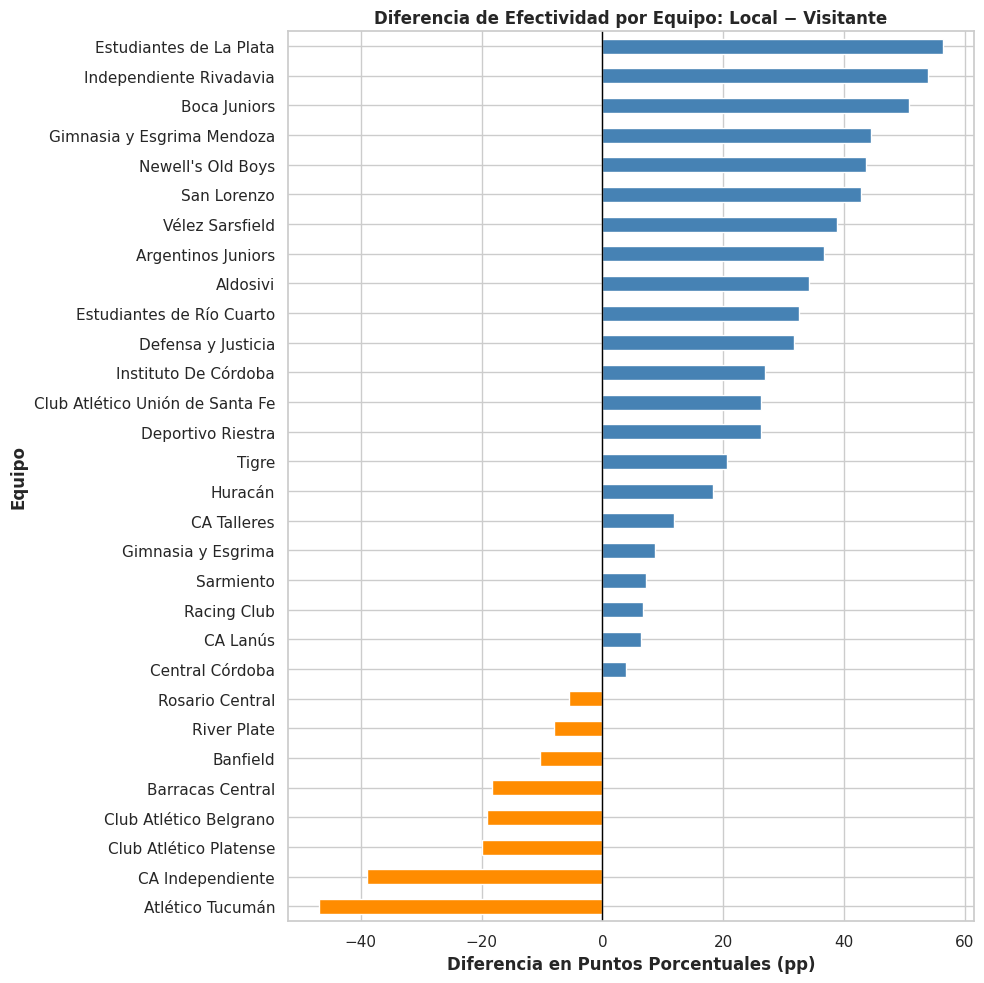

In [ ]:
# ==============================================================================
# ROL 1: ANÁLISIS DE PUNTOS Y EFECTIVIDAD (LOCAL VS. VISITANTE)
# ==============================================================================

# ------------------------------------------------------------------------------
# Paso 1: Asignación de Puntos por Partido


df['Puntos_L'] = np.where(
    df['Resultado (L)'] > df['Resultado (V)'], 3,
    np.where(df['Resultado (L)'] == df['Resultado (V)'], 1, 0)
)

df['Puntos_V'] = np.where(
    df['Resultado (V)'] > df['Resultado (L)'], 3,
    np.where(df['Resultado (V)'] == df['Resultado (L)'], 1, 0)
)

print("=== VERIFICACIÓN DE ASIGNACIÓN DE PUNTOS ===")
display(df[['Local', 'Visitante', 'Resultado (L)', 'Resultado (V)', 'Puntos_L', 'Puntos_V']].head())

# ------------------------------------------------------------------------------
# Paso 2: Efectividad Global de Locales y Visitantes


puntos_posibles = len(df) * 3

resumen_puntos = pd.DataFrame({
    'Condición': ['Local', 'Visitante'],
    'Puntos obtenidos': [df['Puntos_L'].sum(), df['Puntos_V'].sum()],
    'Puntos posibles': [puntos_posibles, puntos_posibles]
})

resumen_puntos['Efectividad (%)'] = (
    resumen_puntos['Puntos obtenidos'] / resumen_puntos['Puntos posibles'] * 100
)

print("=== TABLA GLOBAL DE EFECTIVIDAD DE PUNTOS ===")
display(resumen_puntos.round(2))

# ------------------------------------------------------------------------------
# Paso 3: Agregación e Indicadores por Equipo (Local vs. Visitante)


local = df.groupby('Local')['Puntos_L'].agg(['sum', 'count'])
local.columns = ['Puntos local', 'Partidos local']

visitante = df.groupby('Visitante')['Puntos_V'].agg(['sum', 'count'])
visitante.columns = ['Puntos visitante', 'Partidos visitante']

por_equipo = local.join(visitante)

por_equipo['Efectividad local (%)'] = (
    por_equipo['Puntos local'] / (por_equipo['Partidos local'] * 3) * 100
)

por_equipo['Efectividad visitante (%)'] = (
    por_equipo['Puntos visitante'] / (por_equipo['Partidos visitante'] * 3) * 100
)

por_equipo['Diferencia (pp)'] = (
    por_equipo['Efectividad local (%)'] - por_equipo['Efectividad visitante (%)']
)

por_equipo = por_equipo.sort_values('Diferencia (pp)', ascending=False)

print("=== TABLA DE EFECTIVIDAD Y DIFERENCIA POR EQUIPO ===")
display(por_equipo[[
    'Efectividad local (%)',
    'Efectividad visitante (%)',
    'Diferencia (pp)'
]].round(2))

# ------------------------------------------------------------------------------
# Paso 4: Visualización de la Diferencia de Efectividad por Equipo


datos_grafico = por_equipo.sort_values('Diferencia (pp)')

colores = [
    'steelblue' if valor >= 0 else 'darkorange'
    for valor in datos_grafico['Diferencia (pp)']
]

fig, ax = plt.subplots(figsize=(10, 10))

datos_grafico['Diferencia (pp)'].plot(
    kind='barh',
    ax=ax,
    color=colores
)

ax.axvline(0, color='black', linewidth=1)
ax.set_title('Diferencia de Efectividad por Equipo: Local − Visitante', fontweight='bold', fontsize=12)
ax.set_xlabel('Diferencia en Puntos Porcentuales (pp)', fontweight='bold')
ax.set_ylabel('Equipo', fontweight='bold')

plt.tight_layout()
plt.savefig('diferencia_efectividad.png', dpi=300, bbox_inches='tight')
plt.show()



# Conclusión primer analisis: puntos y efectividad según la localía

En los 194 partidos analizados, los locales consiguieron el 52,58 % de los puntos posibles, mientras que los visitantes obtuvieron el 38,14%. Esto muestra una mayor efectividad al jugar de local, con una diferencia de 14,43 puntos porcentuales.

La diferencia varía entre equipos: Estudiantes de La Plata, Independiente Rivadavia y Boca Juniors presentan las mayores ventajas a favor de la localía. En cambio, Atlético Tucumán e Independiente consiguieron mejores resultados como visitantes.

En los partidos analizados, jugar de local se relaciona con una mayor obtención de puntos en general, aunque no ocurre en todos los equipos ni permite afirmar que la localía sea la única causa de los resultados.

# **## ROL 2 **


Producción Ofensiva: Promedio global de Tiros al arco y xG a favor
---



In [443]:
local = df[['Local', 'Goles esperados (xG) (L)', 'Tiros al arco (L)']].copy()
local.columns = ['Club', 'xG', 'Tiros al arco']
local['Condición'] = 'Local'

visitante = df[['Visitante', 'Goles esperados (xG) (V)', 'Tiros al arco (V)']].copy()
visitante.columns = ['Club', 'xG', 'Tiros al arco']
visitante['Condición'] = 'Visitante'
partidos = pd.concat([local, visitante], ignore_index=True)

promedios = partidos.groupby(['Club', 'Condición'])[
    ['xG', 'Tiros al arco']
].mean().unstack('Condición')

# Caída absoluta al salir: promedio local menos promedio visitante
resumen = pd.DataFrame(index=promedios.index)
resumen['xG local'] = promedios[('xG', 'Local')]
resumen['xG visitante'] = promedios[('xG', 'Visitante')]
resumen['Caída xG'] = resumen['xG local'] - resumen['xG visitante']
resumen['Tiros al arco local'] = promedios[('Tiros al arco', 'Local')]
resumen['Tiros al arco visitante'] = promedios[('Tiros al arco', 'Visitante')]
resumen['Caída tiros al arco'] = (
    resumen['Tiros al arco local'] - resumen['Tiros al arco visitante']
)

resumen = resumen.sort_values('Caída xG', ascending=False)
resumen.round(2)

,xG local,xG visitante,Caída xG,Tiros al arco local,Tiros al arco visitante,Caída tiros al arco
Club,,,,,,
Independiente Rivadavia,2.22,0.90,1.32,5.83,4.43,1.40
Argentinos Juniors,1.88,0.83,1.04,6.60,3.38,3.22
Gimnasia y Esgrima,2.27,1.23,1.04,5.83,3.86,1.98
Huracán,1.67,0.76,0.91,5.00,2.83,2.17
Estudiantes de La Plata,1.94,1.13,0.80,6.43,4.00,2.43
Banfield,1.50,0.92,0.57,4.83,3.14,1.69
Vélez Sarsfield,1.25,0.75,0.50,4.83,3.83,1.00
Club Atlético Unión de Santa Fe,1.39,0.92,0.47,4.83,3.57,1.26
Central Córdoba,1.34,0.91,0.43,4.67,2.71,1.95


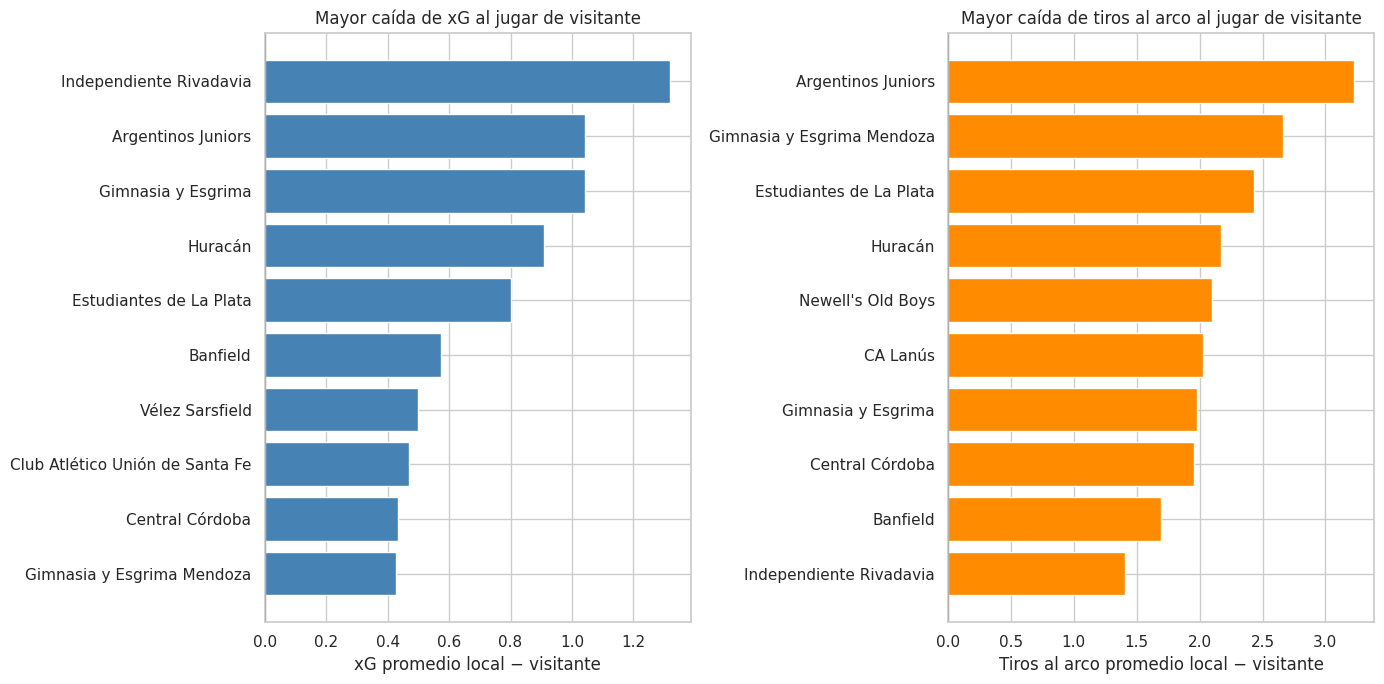

In [444]:

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Mayor caída de xG
top_xg = resumen.nlargest(10, 'Caída xG').sort_values('Caída xG')
axes[0].barh(top_xg.index, top_xg['Caída xG'], color='steelblue')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Mayor caída de xG al jugar de visitante')
axes[0].set_xlabel('xG promedio local − visitante')

# Mayor caída de tiros al arco
top_tiros = resumen.nlargest(10, 'Caída tiros al arco').sort_values('Caída tiros al arco')
axes[1].barh(top_tiros.index, top_tiros['Caída tiros al arco'], color='darkorange')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Mayor caída de tiros al arco al jugar de visitante')
axes[1].set_xlabel('Tiros al arco promedio local − visitante')

plt.tight_layout()
plt.show()

In [445]:
print("Mayores caídas de xG:")
print(resumen.nlargest(5, 'Caída xG')[
    ['xG local', 'xG visitante', 'Caída xG']
].round(2))

print("\nMayores caídas de tiros al arco:")
print(resumen.nlargest(5, 'Caída tiros al arco')[
    ['Tiros al arco local', 'Tiros al arco visitante', 'Caída tiros al arco']
].round(2))

print("\nPromedios globales:")
print(resumen[
    ['xG local', 'xG visitante',
     'Tiros al arco local', 'Tiros al arco visitante']
].mean().round(2))

Mayores caídas de xG:
                         xG local  xG visitante  Caída xG
Club                                                     
Independiente Rivadavia      2.22          0.90      1.32
Argentinos Juniors           1.88          0.83      1.04
Gimnasia y Esgrima           2.27          1.23      1.04
Huracán                      1.67          0.76      0.91
Estudiantes de La Plata      1.94          1.13      0.80

Mayores caídas de tiros al arco:
                            Tiros al arco local  Tiros al arco visitante  \
Club                                                                       
Argentinos Juniors                         6.60                     3.38   
Gimnasia y Esgrima Mendoza                 5.50                     2.83   
Estudiantes de La Plata                    6.43                     4.00   
Huracán                                    5.00                     2.83   
Newell's Old Boys                          4.43                     2.33   

     

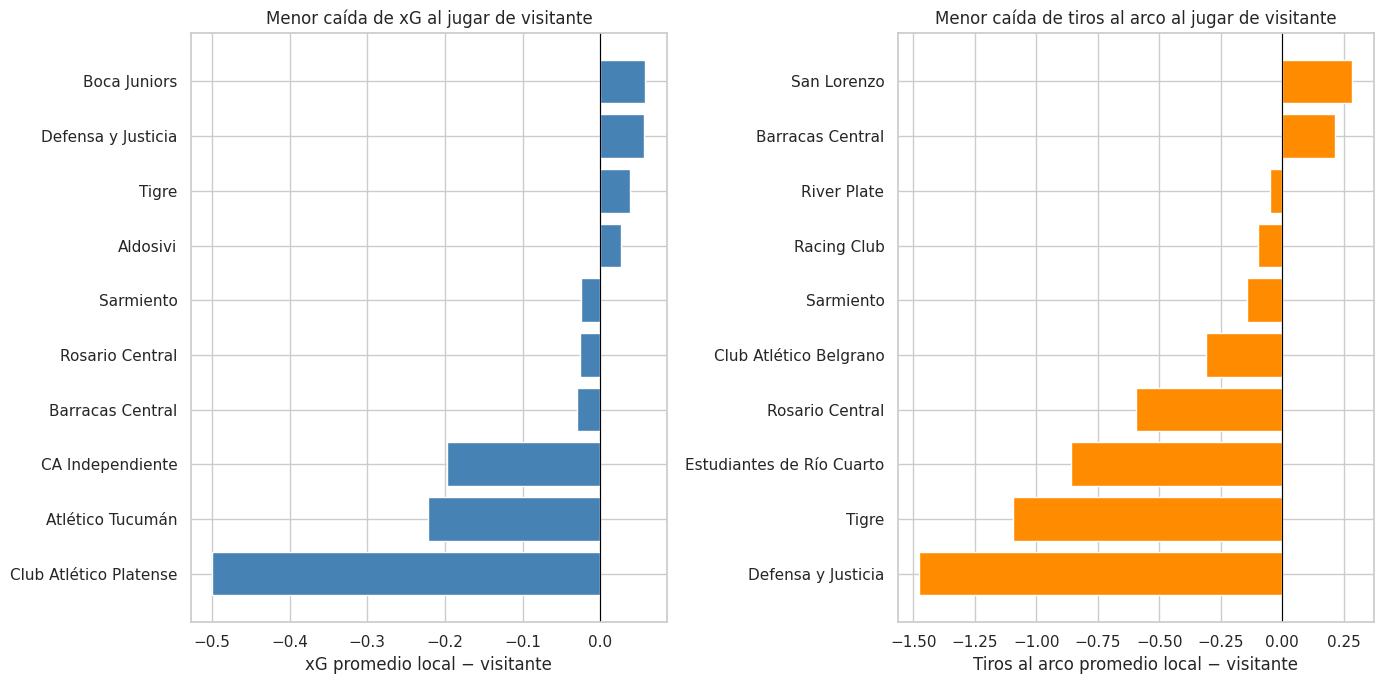

In [446]:

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Menor caída de xG
menor_xg = resumen.nsmallest(10, 'Caída xG').sort_values('Caída xG')
axes[0].barh(menor_xg.index, menor_xg['Caída xG'], color='steelblue')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Menor caída de xG al jugar de visitante')
axes[0].set_xlabel('xG promedio local − visitante')

# Menor caída de tiros al arco
menor_tiros = resumen.nsmallest(
    10, 'Caída tiros al arco'
).sort_values('Caída tiros al arco')

axes[1].barh(
    menor_tiros.index,
    menor_tiros['Caída tiros al arco'],
    color='darkorange'
)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Menor caída de tiros al arco al jugar de visitante')
axes[1].set_xlabel('Tiros al arco promedio local − visitante')

plt.tight_layout()
plt.show()

In [447]:
print("Menor caída de xG:")
print(resumen.nsmallest(5, 'Caída xG')[
    ['xG local', 'xG visitante', 'Caída xG']
].round(2))

print("\nMenor caída de tiros al arco:")
print(resumen.nsmallest(5, 'Caída tiros al arco')[
    ['Tiros al arco local', 'Tiros al arco visitante', 'Caída tiros al arco']
].round(2))

Menor caída de xG:
                        xG local  xG visitante  Caída xG
Club                                                    
Club Atlético Platense      0.99          1.49     -0.50
Atlético Tucumán            0.69          0.92     -0.22
CA Independiente            0.79          0.99     -0.20
Barracas Central            0.99          1.02     -0.03
Rosario Central             1.39          1.41     -0.03

Menor caída de tiros al arco:
                           Tiros al arco local  Tiros al arco visitante  \
Club                                                                      
Defensa y Justicia                        4.86                     6.33   
Tigre                                     3.33                     4.43   
Estudiantes de Río Cuarto                 2.14                     3.00   
Rosario Central                           4.83                     5.43   
Club Atlético Belgrano                    4.86                     5.17   

                         

#Conclusiones

En promedio, los equipos muestran una producción ofensiva menor cuando juegan de visitante: el xG baja de 1,38 a 1,08 (una diferencia de 0,30) y los tiros al arco pasan de 4,74 a 3,85 (una diferencia de 0,89).

Independiente Rivadavia presenta la mayor caída de xG: de 2,22 como local a 0,90 como visitante, una diferencia de 1,32. Le siguen Argentinos Juniors (caída de 1,04) y Gimnasia y Esgrima (caída de 1,04).

En tiros al arco, Argentinos Juniors registra la mayor caída: pasa de 6,60 a 3,38, es decir, 3,22 tiros menos por partido fuera de casa. También destacan Gimnasia y Esgrima Mendoza (−2,67) y Estudiantes de La Plata (−2,43).

Argentinos Juniors, Huracán y Estudiantes de La Plata aparecen entre los cinco clubes con mayores caídas en ambas métricas, lo que sugiere una reducción de su producción ofensiva al salir de su estadio, tanto en volumen de remates como en ocasiones de gol esperadas.

Tambien hay otros casos donde los equipos tienen mayor xG y tiros al arco en condicion de visitante que de local, esta diferencia se calcula como promedio local − promedio visitante. Por eso, una cifra negativa significa que el club tuvo un promedio más alto jugando de visitante.
- xG: Club Atlético Platense muestra el mayor aumento fuera de casa: de 0,99 como local a 1,49 como visitante (diferencia −0,50). También aumentaron Atlético Tucumán (−0,22) y CA Independiente (−0,20). Barracas Central y Rosario Central mantuvieron valores casi iguales entre ambas condiciones.
- Tiros al arco: Defensa y Justicia tuvo el mayor aumento: de 4,86 como local a 6,33 de visitante (diferencia −1,48). Le siguen Tigre (−1,10) y Estudiantes de Río Cuarto (−0,86).
Rosario Central destaca en ambas métricas: su xG se mantuvo prácticamente igual y promedió más tiros al arco de visitante. En conjunto, estos datos muestran que algunos clubes conservaron o incluso aumentaron su producción ofensiva fuera de casa.

In [448]:
# Crear el DataFrame 'Goles' usando 'xG' como 'Goles a favor'
Goles = partidos.rename(columns={'xG': 'Goles a favor'})

In [449]:
# 1. Creamos el alias 'goles' a partir del DataFrame 'partidos' que definiste arriba
goles = partidos.rename(columns={'xG': 'Goles a favor'})

# 2. Tu código agrupado
tabla_goles = goles.groupby(['Club', 'Condición'])['Goles a favor'].agg(
    ['sum', 'mean', 'count']
).unstack('Condición')

# 3. Mostrar el resultado
tabla_goles

sum                mean           count  \
Condición                        Local Visitante     Local Visitante Local   
Club                                                                         
Aldosivi                          5.86      6.65  0.976667  0.950000     6   
Argentinos Juniors                9.38      6.67  1.876000  0.833750     5   
Atlético Tucumán                  4.86      5.50  0.694286  0.916667     7   
Banfield                          8.98      6.47  1.496667  0.924286     6   
Barracas Central                  5.92      7.12  0.986667  1.017143     6   
Boca Juniors                      9.95     11.20  1.658333  1.600000     6   
CA Independiente                  4.75      6.92  0.791667  0.988571     6   
CA Lanús                         10.29      7.94  1.470000  1.323333     7   
CA Talleres                       8.94      6.33  1.277143  1.055000     7   
Central Córdoba                   8.07      6.37  1.345000  0.910000     6   
Club Atlético Belgrano            9.34      7.26  1.334286  1.210000     7   
Club Atlético Platense            6.91      8.92  0.987143  1.486667     7   
Club Atlético Unión de Santa Fe   8.35      6.45  1.391667  0.921429     6   
Defensa y Justicia               11.07      9.15  1.581429  1.525000     7   
Deportivo Riestra                 7.97      4.77  1.138571  0.795000     7   
Estudiantes de La Plata          13.55      6.80  1.935714  1.133333     7   
Estudiantes de Río Cuarto         6.03      4.20  0.861429  0.700000     7   
Gimnasia y Esgrima               13.60      8.58  2.266667  1.225714     6   
Gimnasia y Esgrima Mendoza        8.76      6.20  1.460000  1.033333     6   
Huracán                          11.69      4.56  1.670000  0.760000     7   
Independiente Rivadavia          13.32      6.30  2.220000  0.900000     6   
Instituto De Córdoba              9.59      8.46  1.598333  1.208571     6   
Newell's Old Boys                 8.49      5.27  1.212857  0.878333     7   
Racing Club                      10.40      5.86  1.300000  1.172000     8   
River Plate                      10.25      8.26  1.464286  1.376667     7   
Rosario Central                   8.32      9.89  1.386667  1.412857     6   
San Lorenzo                       6.23      4.89  1.038333  0.698571     6   
Sarmiento                         9.38      8.19  1.340000  1.365000     7   
Tigre                             8.44      9.58  1.406667  1.368571     6   
Vélez Sarsfield                   7.48      4.49  1.246667  0.748333     6   

                                           
Condición                       Visitante  
Club                                       
Aldosivi                                7  
Argentinos Juniors                      8  
Atlético Tucumán                        6  
Banfield                                7  
Barracas Central                        7  
Boca Juniors                            7  
CA Independiente                        7  
CA Lanús                                6  
CA Talleres                             6  
Central Córdoba                         7  
Club Atlético Belgrano                  6  
Club Atlético Platense                  6  
Club Atlético Unión de Santa Fe         7  
Defensa y Justicia                      6  
Deportivo Riestra                       6  
Estudiantes de La Plata                 6  
Estudiantes de Río Cuarto               6  
Gimnasia y Esgrima                      7  
Gimnasia y Esgrima Mendoza              6  
Huracán                                 6  
Independiente Rivadavia                 7  
Instituto De Córdoba                    7  
Newell's Old Boys                       6  
Racing Club                             5  
River Plate                             6  
Rosario Central                         7  
San Lorenzo                             7  
Sarmiento                               6  
Tigre                                   7  
Vélez Sarsfield                         6

In [450]:
tabla_goles = goles.groupby(['Club', 'Condición'])['Goles a favor'].agg(
    ['sum', 'mean', 'count']
).unstack('Condición')

traducciones = {
    'sum': 'Total de goles',
    'mean': 'Promedio por partido',
    'count': 'Partidos jugados'
}

tabla_goles.columns = [
    f'{traducciones[estadistica]} {condicion.lower()}'
    for estadistica, condicion in tabla_goles.columns
]

print("Más goles a favor de local:")
print(tabla_goles.nlargest(5, 'Total de goles local')[
    ['Total de goles local', 'Promedio por partido local', 'Partidos jugados local']
].round(2))

print("\nMás goles a favor de visitante:")
print(tabla_goles.nlargest(5, 'Total de goles visitante')[
    ['Total de goles visitante', 'Promedio por partido visitante', 'Partidos jugados visitante']
].round(2))

Más goles a favor de local:
                         Total de goles local  Promedio por partido local  \
Club                                                                        
Gimnasia y Esgrima                      13.60                        2.27   
Estudiantes de La Plata                 13.55                        1.94   
Independiente Rivadavia                 13.32                        2.22   
Huracán                                 11.69                        1.67   
Defensa y Justicia                      11.07                        1.58   

                         Partidos jugados local  
Club                                             
Gimnasia y Esgrima                            6  
Estudiantes de La Plata                       7  
Independiente Rivadavia                       6  
Huracán                                       7  
Defensa y Justicia                            7  

Más goles a favor de visitante:
                        Total de goles visitante 

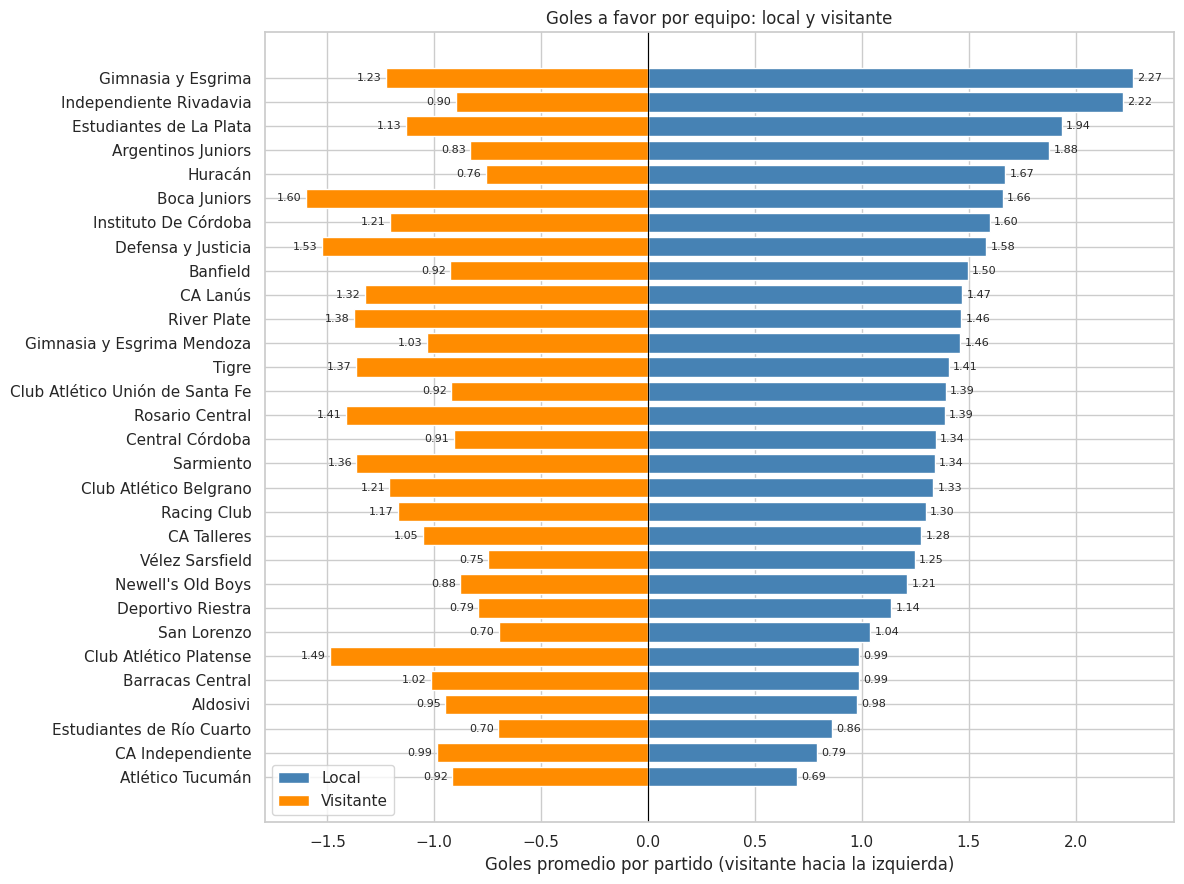

In [451]:

# Ordenar según los equipos con más goles de local
grafico = tabla_goles.sort_values(
    'Promedio por partido local', ascending=True
)

fig, ax = plt.subplots(figsize=(12, 9))

ax.barh(
    grafico.index,
    grafico['Promedio por partido local'],
    label='Local',
    color='steelblue'
)

ax.barh(
    grafico.index,
    -grafico['Promedio por partido visitante'],
    label='Visitante',
    color='darkorange'
)

ax.axvline(0, color='black', linewidth=0.8)
ax.set_yticks(range(len(grafico)))
ax.set_yticklabels(grafico.index)
ax.set_xlabel('Goles promedio por partido (visitante hacia la izquierda)')
ax.set_title('Goles a favor por equipo: local y visitante')
ax.legend()

# Mostrar valores absolutos en ambos lados
for i, (_, fila) in enumerate(grafico.iterrows()):
    ax.text(fila['Promedio por partido local'] + 0.02, i,
            f"{fila['Promedio por partido local']:.2f}",
            va='center', fontsize=8)
    ax.text(-fila['Promedio por partido visitante'] - 0.02, i,
            f"{fila['Promedio por partido visitante']:.2f}",
            va='center', ha='right', fontsize=8)

plt.tight_layout()
plt.show()

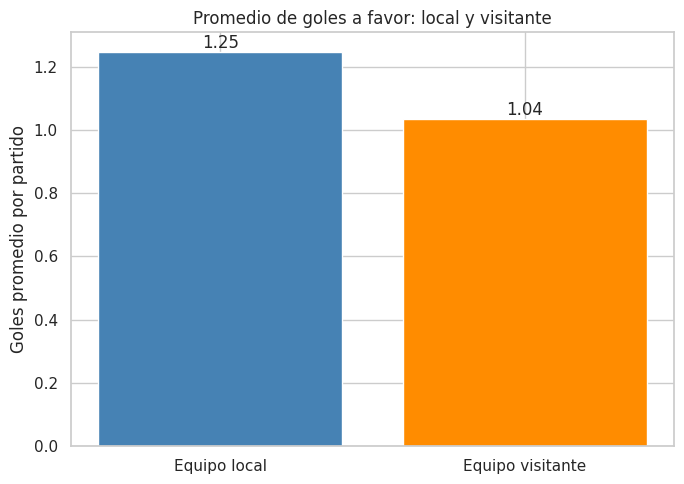

In [452]:

promedios = [
    df['Resultado (L)'].mean(),
    df['Resultado (V)'].mean()
]

condiciones = ['Equipo local', 'Equipo visitante']

plt.figure(figsize=(7, 5))
barras = plt.bar(condiciones, promedios, color=['steelblue', 'darkorange'])

plt.title('Promedio de goles a favor: local y visitante')
plt.ylabel('Goles promedio por partido')

for barra, promedio in zip(barras, promedios):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f'{promedio:.2f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

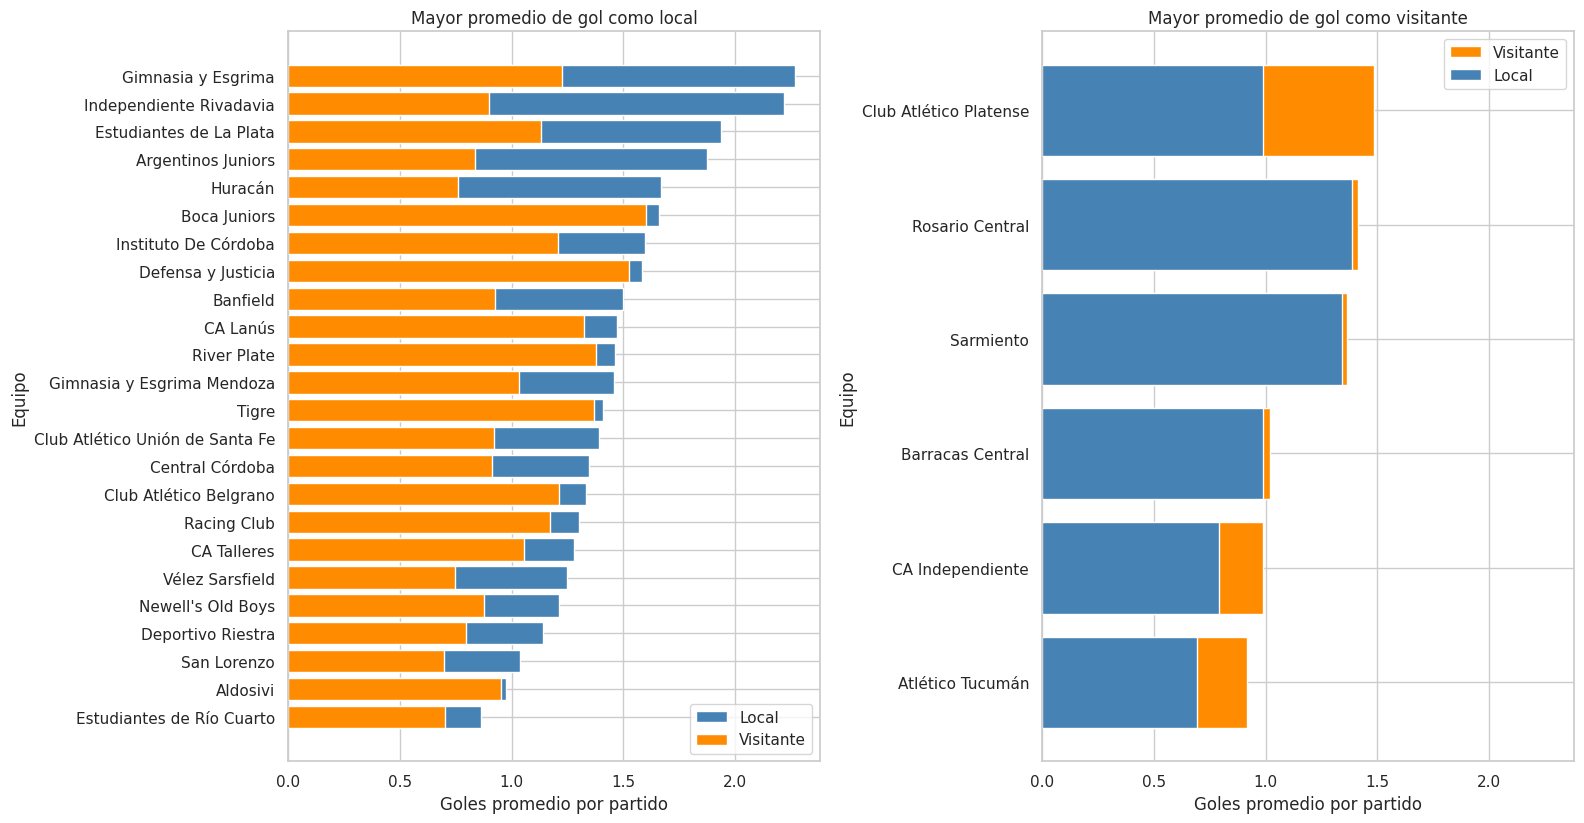

In [ ]:

col_local = 'Promedio por partido local'
col_visitante = 'Promedio por partido visitante'

comparacion = tabla_goles.dropna(subset=[col_local, col_visitante])

mas_local = comparacion[comparacion[col_local] > comparacion[col_visitante]]
mas_local = mas_local.sort_values(col_local, ascending=True)

mas_visitante = comparacion[comparacion[col_visitante] > comparacion[col_local]]
mas_visitante = mas_visitante.sort_values(col_visitante, ascending=True)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, max(6, max(len(mas_local), len(mas_visitante)) * 0.35)),
    sharex=True
)

def dibujar_barras_superpuestas(ax, datos, titulo):
    for i, (_, fila) in enumerate(datos.iterrows()):
        local = fila[col_local]
        visitante = fila[col_visitante]

        # Dibujar primero la barra mayor para que quede debajo
        if local >= visitante:
            ax.barh(i, local, color='steelblue', label='Local' if i == 0 else '')
            ax.barh(i, visitante, color='darkorange', label='Visitante' if i == 0 else '')
        else:
            ax.barh(i, visitante, color='darkorange', label='Visitante' if i == 0 else '')
            ax.barh(i, local, color='steelblue', label='Local' if i == 0 else '')

    ax.set_yticks(range(len(datos)))
    ax.set_yticklabels(datos.index)
    ax.set_title(titulo)
    ax.set_xlabel('Goles promedio por partido')
    ax.set_ylabel('Equipo')
    ax.legend()

dibujar_barras_superpuestas(
    axes[0], mas_local, 'Mayor promedio de gol como local'
)
dibujar_barras_superpuestas(
    axes[1], mas_visitante, 'Mayor promedio de gol como visitante'
)

plt.tight_layout()
plt.show()

Conclusion final:

Vemos que si bien en promedio los equipos locales hacen mas goles que los visitantes, 12 de los 30 equipos de la liga profesional hacen en promedio mas goles de visitante que de local

# **## ROL 3 **

# **Influencia de la Localía en el Control del Juego y la Posesión**

¿Existe una influencia estadísticamente significativa de la localía sobre el porcentaje de posesión del balón, o la tenencia responde a la identidad táctica de los equipos al margen del estadio?

En el fútbol se asume que jugar en el propio estadio genera una presión ambiental y territorial que impele al equipo local a tomar el protagonismo del partido. Evaluar esta variable permite cuantificar si la localía altera la tenencia del balón o si es una dimensión neutra ante el modelo de juego de cada club.

In [454]:
# ==============================================================================
# PASO 1: IMPORTACIÓN DE LIBRERÍAS Y CARGA DEL DATASET --------- PASO A ELIMINAR A LA HORA DE JUNTAR CON EL TRABAJO PRINCIPAL ------------
# ==============================================================================
# Justificación: Establece el entorno reproducible en Google Colab e inspecciona
# las variables de posesión de balón y condición de localía.
# Logro: Carga en memoria del DataFrame y verificación de las 194 observaciones.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

url = 'https://raw.githubusercontent.com/santiagoleguizamon10/TP-labo/main/data/Clausura26_tp_labo.csv'
df = pd.read_csv(url)

print("Dimensiones del dataset:", df.shape)
df.head(3)

Dimensiones del dataset: (194, 21)


,Fecha,Local,Visitante,Resultado (L),Resultado (V),Posesión de balón (L),Posesión de balón (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),...,Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
0,Fecha 1,Club Atlético Belgrano,Rosario Central,2,1,48%,52%,1.50,1.39,13,...,5,3,6,6,10,13,0.0,2.0,0,0
1,Fecha 1,Sarmiento,Argentinos Juniors,2,3,45%,55%,1.50,1.42,12,...,3,5,7,2,15,14,3.0,6.0,0,1
2,Fecha 1,Defensa y Justicia,Aldosivi,1,1,72%,28%,1.06,0.59,15,...,5,3,6,2,9,15,2.0,3.0,0,0


In [455]:
# ==============================================================================
# PASO 2: LIMPIEZA DE DATOS Y CONSTRUCCIÓN DE LA BRECHA TERRITORIAL ------- PASO A REESTRUCTURAR A LA HORA DE JUNTAR CON EL TRABAJO PRINCIPAL -------
# ==============================================================================
# Justificación: Convierte la posesión de texto (%) a flotante numérico y calcula
# la diferencia neta de posesión entre el local y el visitante (Dif_Posesion).
# Logro: Habilita el cálculo de medias, medianas y desviaciones estándar.

# 1. Conversión de tipo de dato (string con % a float)
df['Posesion_L_num'] = df['Posesión de balón (L)'].str.rstrip('%').astype(float)
df['Posesion_V_num'] = df['Posesión de balón (V)'].str.rstrip('%').astype(float)

# 2. Margen de ventaja en la tenencia del local
df['Dif_Posesion'] = df['Posesion_L_num'] - df['Posesion_V_num']

print("Limpieza completada.")
print(f"Posesión Promedio Local: {df['Posesion_L_num'].mean():.2f}%")
print(f"Posesión Promedio Visitante: {df['Posesion_V_num'].mean():.2f}%")

Limpieza completada.
Posesión Promedio Local: 51.05%
Posesión Promedio Visitante: 48.95%


**A) Análisis Global y Distribución del Efecto Campo en la Posesión**

En esta sección se analiza si la condición de localía genera un sesgo cuantitativo en el porcentaje de posesión de balón a nivel general en el Torneo Clausura 2026. Para ello, se calculan las medidas de tendencia central y se ejecuta una prueba $t$ de Student para muestras pareadas, evaluando la significatividad estadística de la brecha territorial. A modo de síntesis, se construye la visualización principal del bloque (diagrama de caja Boxplot superpuesto con Stripplot de eventos individuales), comparando de manera directa la mediana y la variabilidad de la tenencia según la condición de juego (Local vs. Visitante).

Posesión Promedio Local: 51.05% | Visitante: 48.95%
Mediana Posesión Local: 51.0% | Visitante: 49.0%
Partidos con Posesión Local > 50%: 53.1%
Prueba t pareada: t-stat = 1.1816, p-value = 0.2388


/tmp/ipykernel_589/1282124277.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


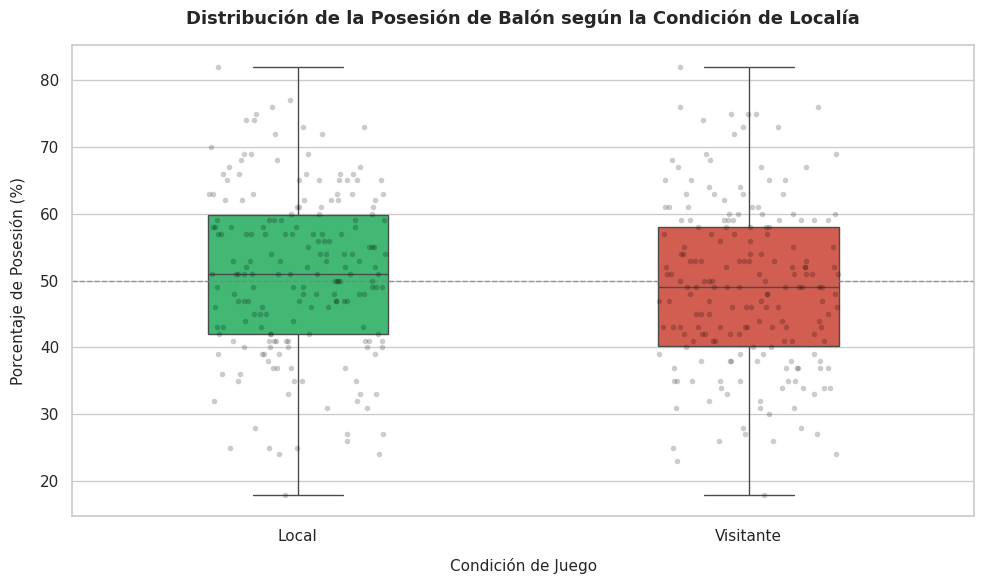

In [456]:
# ==============================================================================
# BLOQUE A: EVALUACIÓN GLOBAL Y DISTRIBUCIÓN DE LA POSESIÓN (LOCAL VS. VISITANTE)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Cuentas y prueba estadística global
mediana_L = df['Posesion_L_num'].median()
mediana_V = df['Posesion_V_num'].median()
pct_mayor_50 = (df['Posesion_L_num'] > 50).mean() * 100

t_stat, p_val = stats.ttest_rel(df['Posesion_L_num'], df['Posesion_V_num'])

print(f"Posesión Promedio Local: {df['Posesion_L_num'].mean():.2f}% | Visitante: {df['Posesion_V_num'].mean():.2f}%")
print(f"Mediana Posesión Local: {mediana_L:.1f}% | Visitante: {mediana_V:.1f}%")
print(f"Partidos con Posesión Local > 50%: {pct_mayor_50:.1f}%")
print(f"Prueba t pareada: t-stat = {t_stat:.4f}, p-value = {p_val:.4f}")

# 2. Visualización Principal (Gráfico 3)
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

df_melted = df.melt(value_vars=['Posesion_L_num', 'Posesion_V_num'], var_name='Condición', value_name='Posesión (%)')
df_melted['Condición'] = df_melted['Condición'].map({'Posesion_L_num': 'Local', 'Posesion_V_num': 'Visitante'})

sns.boxplot(
    data=df_melted,
    x='Condición',
    y='Posesión (%)',
    palette=['#2ecc71', '#e74c3c'],
    ax=ax,
    width=0.4
)

sns.stripplot(
    data=df_melted,
    x='Condición',
    y='Posesión (%)',
    color='black',
    alpha=0.2,
    jitter=0.2,
    size=4,
    ax=ax
)

ax.set_title('Distribución de la Posesión de Balón según la Condición de Localía', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Condición de Juego', fontsize=11, labelpad=10)
ax.set_ylabel('Porcentaje de Posesión (%)', fontsize=11, labelpad=10)
ax.axhline(50, color='gray', linestyle='--', linewidth=1, alpha=0.7)

plt.tight_layout()
plt.savefig('grafico3_rol3_localia_pura.png', dpi=300)
plt.show()

**B) Aislamiento por Club y Ranking del "Efecto Empuje" Territorial**

Para evitar enmascarar comportamientos heterogéneos bajo el promedio general, se efectúa una agregación por institución (groupby) que calcula el diferencial de posesión de cada equipo ($\text{Efecto\_Localia\_Pos} = \bar{P}_L - \bar{P}_V$). Esta métrica aísla la influencia real del estadio sobre la propuesta táctica.

El cálculo se complementa con un gráfico de barras horizontales ordenado por diferencial, permitiendo identificar de forma nítida qué equipos transforman su protagonismo al jugar en casa ($+10\%$ a $+14\%$ de tenencia) y en cuáles el modelo táctico prevalece sin importar la sede.

/tmp/ipykernel_589/3342419833.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


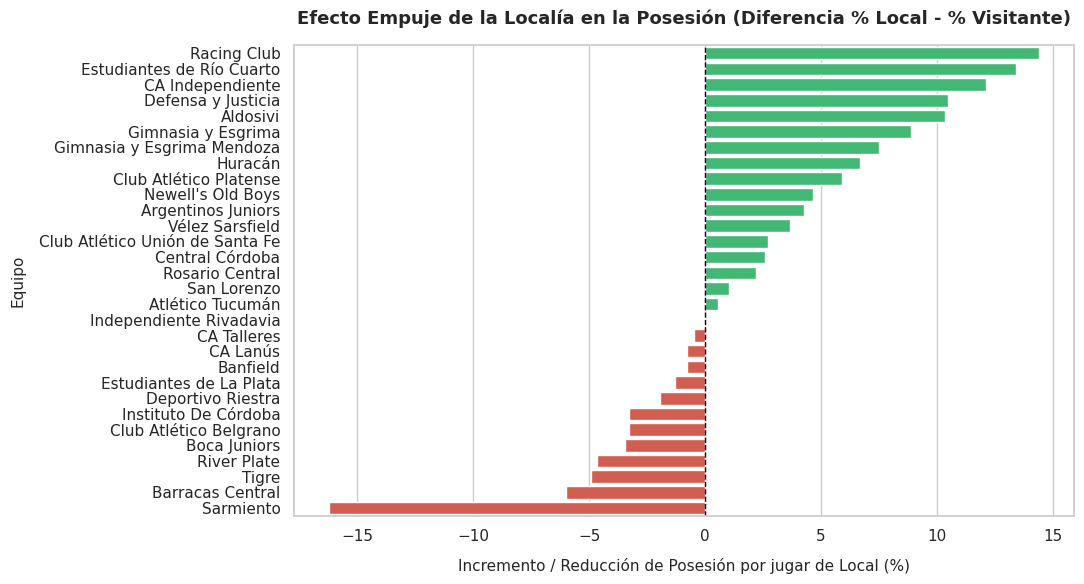

In [457]:
# ==============================================================================
# BLOQUE B: AGREGACIÓN POR CLUB Y RANKING DEL EFECTO EMPUJE EN LA POSESIÓN
# ==============================================================================
# 1. Agregación y cálculo del diferencial por equipo
locales = df.groupby('Local')['Posesion_L_num'].agg(['mean', 'count']).rename(columns={'mean': 'Pos_Local_Prom', 'count': 'PJ_L'})
visitantes = df.groupby('Visitante')['Posesion_V_num'].agg(['mean', 'count']).rename(columns={'mean': 'Pos_Visitante_Prom', 'count': 'PJ_V'})

equipos = locales.join(visitantes)
equipos['Efecto_Localia_Pos'] = equipos['Pos_Local_Prom'] - equipos['Pos_Visitante_Prom']
equipos_ordenados = equipos.sort_values(by='Efecto_Localia_Pos', ascending=False)

# 2. Visualización Auxiliar (Ranking del Efecto Empuje)
top_bottom_efecto = pd.concat([equipos_ordenados]).reset_index()

fig2, ax2 = plt.subplots(figsize=(11, 6))
colors = ['#2ecc71' if val > 0 else '#e74c3c' for val in top_bottom_efecto['Efecto_Localia_Pos']]

sns.barplot(
    data=top_bottom_efecto,
    x='Efecto_Localia_Pos',
    y='Local',
    palette=colors,
    ax=ax2
)

ax2.set_title('Efecto Empuje de la Localía en la Posesión (Diferencia % Local - % Visitante)', fontsize=13, fontweight='bold', pad=15)
ax2.set_xlabel('Incremento / Reducción de Posesión por jugar de Local (%)', fontsize=11, labelpad=10)
ax2.set_ylabel('Equipo', fontsize=11, labelpad=10)
ax2.axvline(0, color='black', linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig('grafico_auxiliar_efecto_empuje.png', dpi=300)
plt.show()

**Conclusiones del Bloque centradas en la Localía**

1. Magnitud del Efecto Campo en la Posesión:

    La localía ejerce un leve predominio en la tenencia del balón, registrando una media del 51.05% de posesión para el local frente al 48.95% para el visitante (un margen promedio de +2.14%). En el 53.1% de los encuentros, el equipo local supera el 50% de tenencia.

2. Inexistencia de un Impacto Absoluto:

    La prueba de hipótesis refleja que el incremento del +2.14% no es estadísticamente determinante (p=0.2388). Esto demuestra que la localía no impone de manera automática el monopolio de la pelota.

3. Variabilidad Táctica por Club ("Efecto Empuje"):

    La influencia del estadio en la posesión varía de acuerdo con el perfil del equipo:

* Localías Potenciadoras del Protagonismo: En clubes como Racing Club (+14.4%), Estudiantes de Río Cuarto (+13.4%) e Independiente (+12.1%), jugar en casa transforma drásticamente la actitud del equipo, haciendo que asuman el control del balón.

* Prevalencia del Estilo sobre el Estadio: En instituciones con modelos de juego fuertemente arraigados, como River Plate (−4.6%) o Boca Juniors (−3.5%), los equipos promedian mayor posesión en condición de visitante que de local, demostrando que su modelo de juego prevalece por encima del factor campo.

# **##ROL 4 **

### 3. Formulación de Preguntas Específicas y Métricas Disciplinarias:

Con el objetivo de evaluar si la condición de localía está acompañada de un sesgo arbitral o disciplinario, este bloque aborda las siguientes preguntas de investigación:

1. **¿Existe una disparidad en el volumen de infracciones y amonestaciones entre locales y visitantes?**
2. **¿El criterio o severidad del arbitraje (medido como tarjetas por falta cometida) es más estricto contra el equipo visitante?**

**Transformaciones aplicadas:**
- Imputación de valores nulos en tarjetas amarillas con cero (asumiendo ausencia de sanciones en registros vacíos).
- Creación de variables consolidadas de disciplinamiento (`Total_Tarjetas_Local` y `Total_Tarjetas_Vis`).
- Construcción del ratio de severidad arbitral (`Ratio_Tarj_Falta`).

In [458]:
# 3. Limpieza de datos y principales caracteristicas para responder preguntas planteadas.
# A) Imputación de nulos en tarjetas amarillas con 0
df['Tarjetas amarillas (L)'] = df['Tarjetas amarillas (L)'].fillna(0)
df['Tarjetas amarillas (V)'] = df['Tarjetas amarillas (V)'].fillna(0)

# B) Compara los goles de cada fila (partido) y clasifica el escenario
def calcular_resultado(row):
    if row['Resultado (L)'] > row['Resultado (V)']:
        return 'Gana Local'
    elif row['Resultado (L)'] < row['Resultado (V)']:
        return 'Gana Visitante'
    else:
        return 'Empate'

# C) Aplica la función a todo el DataFrame fila por fila (axis=1)
df['Resultado_Partido'] = df.apply(calcular_resultado, axis=1)

# D) Creación de métricas disciplinarias consolidadas (Amarillas + Rojas)
df['Total_Tarjetas_Local'] = df['Tarjetas amarillas (L)'] + df['Tarjetas rojas (L)']
df['Total_Tarjetas_Vis'] = df['Tarjetas amarillas (V)'] + df['Tarjetas rojas (V)']

# E) Brechas disciplinarias (Visitante - Local)
df['Dif_Faltas'] = df['Faltas (V)'] - df['Faltas (L)']
df['Dif_Tarjetas'] = df['Total_Tarjetas_Vis'] - df['Total_Tarjetas_Local']

# F) Ratio de severidad arbitral (Tarjetas por Falta cometida)
df['Ratio_Tarj_Falta_L'] = df['Total_Tarjetas_Local'] / df['Faltas (L)'].replace(0, np.nan)
df['Ratio_Tarj_Falta_V'] = df['Total_Tarjetas_Vis'] / df['Faltas (V)'].replace(0, np.nan)

df[['Fecha', 'Local', 'Visitante', 'Faltas (L)', 'Faltas (V)', 'Total_Tarjetas_Local', 'Total_Tarjetas_Vis']].head(3) #.head unicamente para control visual





,Fecha,Local,Visitante,Faltas (L),Faltas (V),Total_Tarjetas_Local,Total_Tarjetas_Vis
0,Fecha 1,Club Atlético Belgrano,Rosario Central,10,13,0.0,2.0
1,Fecha 1,Sarmiento,Argentinos Juniors,15,14,3.0,7.0
2,Fecha 1,Defensa y Justicia,Aldosivi,9,15,2.0,3.0


### 4. Análisis Estadístico Agrupado y Evaluación del Sesgo Disciplinario:

Para responder a las preguntas planteadas sobre la existencia de un sesgo arbitral favorable al equipo local, este bloque aplica técnicas de agrupacion (`groupby` y métricas descriptivas):

1. **Comparación global de promedios:** Se evalúa si el equipo visitante comete más infracciones y/o recibe más sanciones disciplinarias en promedio a lo largo de la liga.
2. **Evaluación de la severidad arbitral:** Se mide la relación entre infracciones cometidas y tarjetas mostradas (Severidad = Tarjetas cada 10 faltas) para ambos escenarios.
3. **Comportamiento según el resultado:** Se analiza el volumen de faltas y tarjetas desagregado por el desenlace del encuentro (Gana Local, Empate, Gana Visitante).

In [459]:
# 4. Análisis estadístico agrupado (groupby) y comparación disciplinaria.

# A) Creación de la Tabla Comparativa General (Medias globales de la liga)
resumen_disciplina = pd.DataFrame({
    'Métrica Disciplinaria': [
        'Faltas Promedio por Partido',
        'Tarjetas Amarillas Promedio',
        'Tarjetas Rojas Promedio',
        'Total Tarjetas Promedio',
        'Severidad (Tarjetas cada 10 faltas)'
    ],
    'Local': [
        df['Faltas (L)'].mean(),
        df['Tarjetas amarillas (L)'].mean(),
        df['Tarjetas rojas (L)'].mean(),
        df['Total_Tarjetas_Local'].mean(),
        df['Ratio_Tarj_Falta_L'].mean() * 10
    ],
    'Visitante': [
        df['Faltas (V)'].mean(),
        df['Tarjetas amarillas (V)'].mean(),
        df['Tarjetas rojas (V)'].mean(),
        df['Total_Tarjetas_Vis'].mean(),
        df['Ratio_Tarj_Falta_V'].mean() * 10
    ]
})

# B) Cálculo de la diferencia neta entre la condición de visitante y local
resumen_disciplina['Diferencia (Vis - Loc)'] = resumen_disciplina['Visitante'] - resumen_disciplina['Local']

# C) Muestra en pantalla de la comparación general
print("=== TABLA 1: COMPARACIÓN GENERAL DISCIPLINARIA ===")
display(resumen_disciplina.round(2))

# D) Agrupamiento por resultado del encuentro para analizar variaciones según el trámite del partido
resumen_por_resultado = df.groupby('Resultado_Partido')[
    ['Faltas (L)', 'Faltas (V)', 'Total_Tarjetas_Local', 'Total_Tarjetas_Vis']
].mean()

# E) Muestra en pantalla del desglose por resultado
print("\n=== TABLA 2: PROMEDIOS DISCIPLINARIOS SEGÚN EL RESULTADO DE CADA MATCH ===")
display(resumen_por_resultado.round(2))

=== TABLA 1: COMPARACIÓN GENERAL DISCIPLINARIA ===


,Métrica Disciplinaria,Local,Visitante,Diferencia (Vis - Loc)
0,Faltas Promedio por Partido,11.79,12.19,0.40
1,Tarjetas Amarillas Promedio,2.02,2.51,0.49
2,Tarjetas Rojas Promedio,0.06,0.12,0.06
3,Total Tarjetas Promedio,2.07,2.63,0.56
4,Severidad (Tarjetas cada 10 faltas),1.81,2.24,0.43



=== TABLA 2: PROMEDIOS DISCIPLINARIOS SEGÚN EL RESULTADO DE CADA MATCH ===


,Faltas (L),Faltas (V),Total_Tarjetas_Local,Total_Tarjetas_Vis
Resultado_Partido,,,,
Empate,11.76,12.07,2.00,2.54
Gana Local,11.98,12.44,1.89,2.82
Gana Visitante,11.54,11.93,2.41,2.43


### 5. Visualización Gráfica del Sesgo Disciplinario y Criterio Arbitral:

Con el objetivo de volcar una visualización clara en el informe, este bloque genera un gráfico comparativo de barras dobles que evidencia:

1. **La disparidad en métricas clave:** Faltas acumuladas, total de sanciones y el ratio de severidad por cada 10 infracciones entre el equipo local y el visitante.


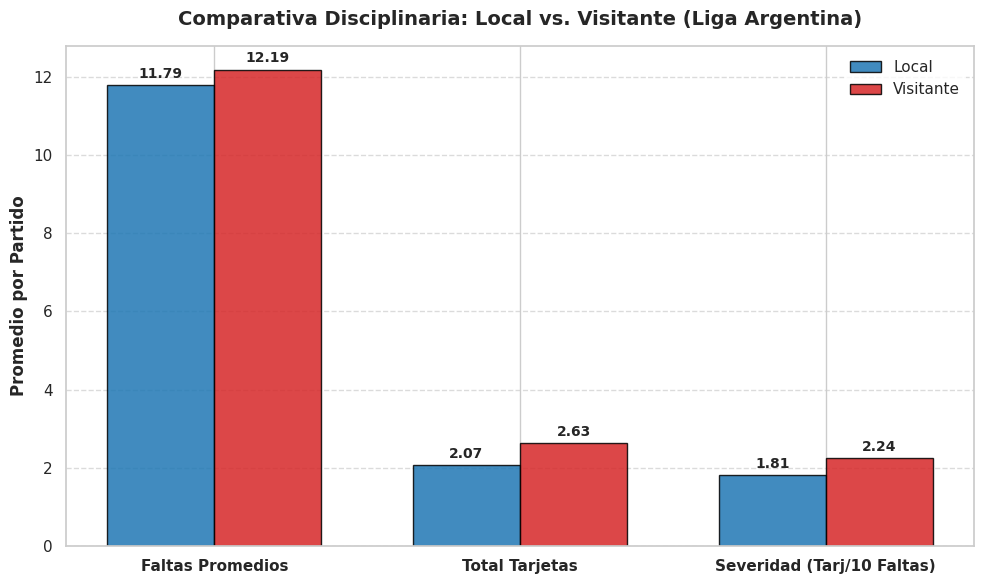

In [460]:
# 5. Generación de gráfico comparativo disciplinario y exportación para Overleaf.

# A) Configuración del lienzo y subplots
fig, ax = plt.subplots(figsize=(10, 6))

# B) Selección de métricas clave a graficar
metricas = ['Faltas Promedios', 'Total Tarjetas', 'Severidad (Tarj/10 Faltas)']
valores_local = [11.79, 2.07, 1.81]
valores_vis = [12.19, 2.63, 2.24]

x = np.arange(len(metricas))
ancho_barra = 0.35

# C) Trazado de las barras comparativas
barras1 = ax.bar(x - ancho_barra/2, valores_local, ancho_barra, label='Local', color='#1f77b4', edgecolor='black', alpha=0.85)
barras2 = ax.bar(x + ancho_barra/2, valores_vis, ancho_barra, label='Visitante', color='#d62728', edgecolor='black', alpha=0.85)

# D) Personalización de etiquetas y títulos
ax.set_ylabel('Promedio por Partido', fontsize=12, fontweight='bold')
ax.set_title('Comparativa Disciplinaria: Local vs. Visitante (Liga Argentina)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metricas, fontsize=11, fontweight='bold')
ax.legend(frameon=True, facecolor='white', edgecolor='none')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# E) Inserción de valores numéricos sobre cada barra (data labels)
def agregar_etiquetas(barras):
    for barra in barras:
        alto = barra.get_height()
        ax.annotate(f'{alto:.2f}',
                    xy=(barra.get_x() + barra.get_width() / 2, alto),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

agregar_etiquetas(barras1)
agregar_etiquetas(barras2)

plt.tight_layout()

# F) Guardado de la imagen para importar en la carpeta del informe de GitHub/Overleaf
plt.savefig('grafico_disciplina_localia.png', dpi=300, bbox_inches='tight')
plt.show()



### 6. Síntesis e Interpretación de Hallazgos Disciplinarios:

A partir del análisis cuantitativo y la visualización realizada, se confirman las siguientes conclusiones respecto al sesgo disciplinario:

1. **Evidencia de Sesgo Arbitral:** Existe una disparidad sistemática entre la condición de local y visitante. Mientras que las infracciones cometidas son similares (11.79 local vs. 12.19 visitante), el visitante recibe **0.56 tarjetas adicionales por partido** (+27% de amonestaciones y el doble de expulsiones).
2. **Mayor Severidad por Infracción:** El criterio de juzgamiento no es simétrico: la visita recibe **2.24 tarjetas por cada 10 faltas**, comparado a las **1.81 del local** (un criterio un 23.7% más severo).
3. **Comportamiento según el Trámite:** En los partidos con victoria local, la brecha de amonestaciones alcanza su máximo histórico (2.82 tarjetas al visitante vs. 1.89 al local), evidenciando que el control disciplinario del visitante se intensifica cuando el local domina en el marcador.

### 7. Matriz de Control de Posesión y Severidad Arbitral

Evaluamos si el dominio del balón atenúa o agrava el rigor arbitral sobre el equipo visitante:

En criollo : Cuando el visitante tiene más la pelota pero comete faltas tácticas para cortar el avance local, ¿recibe un castigo desproporcionado comparado a cuando el local recupera la pelota?

1. **Clasificación por dominio del balón:** Se dividen los encuentros según si el local domina la posesión (> 55%), la visita domina (> 55%) o si el trámite es disputado/parejo (45% a 55%).
2. **Severidad según iniciativa:** Se analiza si el ratio de severidad (tarjetas cada 10 faltas) sobre el visitante varía cuando este debe defenderse la mayor parte del partido vs. cuando asume el protagonismo con el balón.

In [461]:
# A) Limpieza y conversión de las columnas de posesión a tipo numérico
# Eliminamos el símbolo '%' si existe y convertimos a flotante
df['Posesion_L_num'] = df['Posesión de balón (L)'].astype(str).str.replace('%', '').astype(float)
df['Posesion_V_num'] = df['Posesión de balón (V)'].astype(str).str.replace('%', '').astype(float)

In [462]:
# 7. Análisis del impacto del dominio de la posesión sobre el criterio disciplinario.
# B) Clasificación de los partidos según la posesión de balón
condiciones_posesion = [
    df['Posesion_L_num'] > 55,
    df['Posesion_V_num'] > 55
]
opciones_posesion = ['Dominio Local', 'Dominio Visitante']

df['Escenario_Posesion'] = np.select(condiciones_posesion, opciones_posesion, default='Partido Parejo')

# C) Agrupamiento por escenario de posesión para calcular promedios
analisis_posesion_disciplina = df.groupby('Escenario_Posesion')[
    ['Faltas (L)', 'Faltas (V)', 'Ratio_Tarj_Falta_L', 'Ratio_Tarj_Falta_V']
].mean()

# D) Escalamiento de ratios a 'Tarjetas cada 10 Faltas'
analisis_posesion_disciplina['Severidad_Local (Tarj/10 F)'] = analisis_posesion_disciplina['Ratio_Tarj_Falta_L'] * 10
analisis_posesion_disciplina['Severidad_Visita (Tarj/10 F)'] = analisis_posesion_disciplina['Ratio_Tarj_Falta_V'] * 10

# E) Visualización en pantalla de la Tabla 3
print("=== TABLA 3: SEVERIDAD DISCIPLINARIA SEGÚN EL DOMINIO DE LA POSESIÓN ===")
display(analisis_posesion_disciplina[[
    'Faltas (L)', 'Faltas (V)', 'Severidad_Local (Tarj/10 F)', 'Severidad_Visita (Tarj/10 F)'
]].round(2))

=== TABLA 3: SEVERIDAD DISCIPLINARIA SEGÚN EL DOMINIO DE LA POSESIÓN ===


,Faltas (L),Faltas (V),Severidad_Local (Tarj/10 F),Severidad_Visita (Tarj/10 F)
Escenario_Posesion,,,,
Dominio Local,10.41,13.28,1.96,2.09
Dominio Visitante,12.97,10.64,1.64,2.12
Partido Parejo,12.34,12.34,1.80,2.53


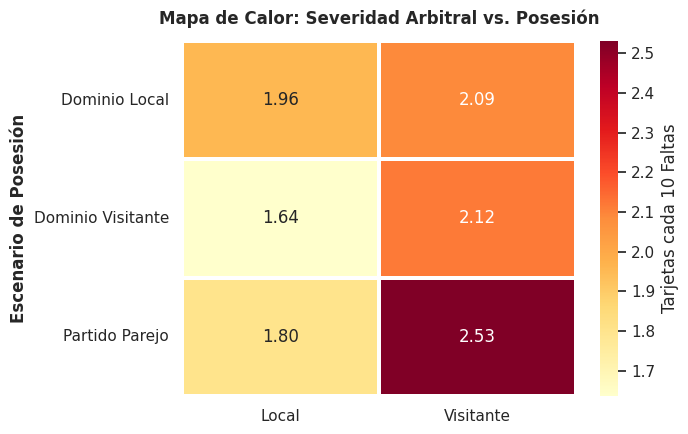

In [463]:


# Extraer solo las columnas de severidad para la matriz
matriz_severidad = analisis_posesion_disciplina[['Severidad_Local (Tarj/10 F)', 'Severidad_Visita (Tarj/10 F)']]
matriz_severidad.columns = ['Local', 'Visitante']

plt.figure(figsize=(7, 4.5))
sns.heatmap(matriz_severidad, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={'label': 'Tarjetas cada 10 Faltas'}, linewidths=1.5)

plt.title('Mapa de Calor: Severidad Arbitral vs. Posesión', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Escenario de Posesión', fontweight='bold')
plt.tight_layout()

plt.savefig('heatmap_posesion_severidad.png', dpi=300)
plt.show()

### 8. Síntesis Integradora y Conclusiones del Factor Disciplinario

Del cruce entre faltas, tarjetas, resultado y manejo de la pelota, la estadística deja en evidencia cómo se juega el partido "de guapo" en la cancha:

1. **La balanza siempre se inclina para el local:** Existe una asimetría sistemática en el arbitro. A pesar de que la cantidad de faltas cometidas es similar entre ambos, la tendencia del árbitro es mucho más pesada con el visitante: la visita recibe **2,24 tarjetas cada 10 faltas**, contra **1,81** del dueño de casa (un rigor **+23,7% mayor**).
2. **El resultado aprieta al visitante:** El sesgo en el juzgamiento se vuelve todavía más marcado cuando el local va ganando. Con el resultado a favor del de casa, la visita es la que termina pagando el costo disciplinario con un pico de amonestaciones.
3. **Tener la pelota no te salva del rigor:** Adueñarse del trámite no exime al visitante del castigo. En escenarios de **Dominio Visitante**, la severidad hacia la visita sigue siendo claramente superior (**2,12 vs. 1,64**). Para colmo, la brecha más amplia no se da cuando te inclinan la cancha, sino en los **Partidos Parejos**: ahí el árbitro le cobra con el doble de rigor a la visita (**2,53 tarjetas/10 faltas** frente a **1,80** para el local).

### 9. Matriz de Sensibilidad por Intensidad del Partido: ¿El sesgo aparece siempre o solo cuando se "pica" el partido?

Para no quedarnos solo con el promedio general, nos preguntamos si la mano facil al bolsillo del árbitro con el visitante es una constante de todos los fines de semana o si aparece cuando el trámite se calienta y la hinchada empieza a empujar.

Para no fijar un criterio a ojo sobre qué es un partido "picante", usamos la función `pd.qcut(q=3)` de Pandas. Esto divide el total de partidos del torneo en tres tercios estadísticamente iguales según la cantidad de faltas cobradas:

1. **Limpio (Pocas Faltas):** El tercio de partidos más fluidos y con menos roces.
2. **Intensidad Media:** El tramo medio de fricción habitual en la liga.
3. **Picado (Muchas Faltas):** El tercio de partidos más trabados, cortados y disputados.

**¿Qué buscamos medir?**
Evaluamos si la brecha de severidad (tarjetas cada 10 faltas entre la visita y el local) se mantiene pareja o si se dispara a medida que el partido sube de temperatura.

In [464]:
# 9. Matriz de Sensibilidad por Intensidad del Partido (Términos Criollos)

# A) Creación de la variable de intensidad dividiendo el total de faltas en 3 tercios
df['Total_Faltas_Partido'] = df['Faltas (L)'] + df['Faltas (V)']
df['Intensidad_Partido'] = pd.qcut(
    df['Total_Faltas_Partido'],
    q=3,
    labels=['Partido Limpio', 'Intensidad Media', 'Partido Picado']
)

# B) Agrupamiento para calcular los promedios de severidad según la temperatura del partido
matriz_intensidad = df.groupby('Intensidad_Partido', observed=False)[
    ['Faltas (L)', 'Faltas (V)', 'Ratio_Tarj_Falta_L', 'Ratio_Tarj_Falta_V']
].mean()

# C) Conversión a 'Tarjetas cada 10 Faltas'
matriz_intensidad['Severidad_Local (Tarj/10 F)'] = matriz_intensidad['Ratio_Tarj_Falta_L'] * 10
matriz_intensidad['Severidad_Visita (Tarj/10 F)'] = matriz_intensidad['Ratio_Tarj_Falta_V'] * 10

# D) Cálculo de la Brecha Disciplinaria
matriz_intensidad['Brecha_Severidad (V - L)'] = (
    matriz_intensidad['Severidad_Visita (Tarj/10 F)'] - matriz_intensidad['Severidad_Local (Tarj/10 F)']
)

# E) Despliegue de la Tabla 4 en pantalla
print("=== TABLA 4: MATRIZ DE SENSIBILIDAD ARBITRAL SEGÚN INTENSIDAD DEL PARTIDO ===")
display(matriz_intensidad[[
    'Faltas (L)', 'Faltas (V)',
    'Severidad_Local (Tarj/10 F)', 'Severidad_Visita (Tarj/10 F)',
    'Brecha_Severidad (V - L)'
]].round(2))

=== TABLA 4: MATRIZ DE SENSIBILIDAD ARBITRAL SEGÚN INTENSIDAD DEL PARTIDO ===


,Faltas (L),Faltas (V),Severidad_Local (Tarj/10 F),Severidad_Visita (Tarj/10 F),Brecha_Severidad (V - L)
Intensidad_Partido,,,,,
Partido Limpio,9.51,9.68,1.99,2.50,0.51
Intensidad Media,12.31,12.20,1.78,2.00,0.22
Partido Picado,14.23,15.39,1.62,2.12,0.50


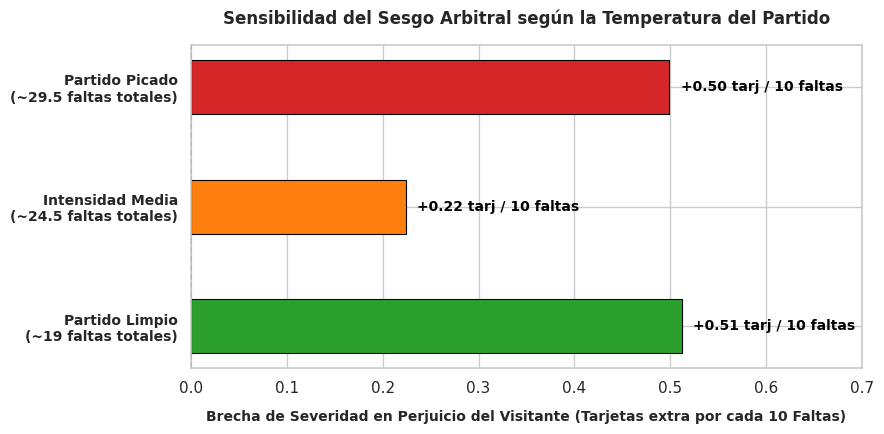

In [ ]:


# Configuración del estilo base
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 4.5))

# Datos extraídos de la Tabla 4
escenarios = [
    'Partido Limpio\n(~19 faltas totales)',
    'Intensidad Media\n(~24.5 faltas totales)',
    'Partido Picado\n(~29.5 faltas totales)'
]
brechas = matriz_intensidad['Brecha_Severidad (V - L)']

# Paleta de colores semántica para diferenciar los climas del partido
colores_clima = ['#2ca02c', '#ff7f0e', '#d62728'] # Verde, Naranja, Rojo

# Creación de las barras horizontales
bars = ax.barh(escenarios, brechas, color=colores_clima, height=0.45, edgecolor='black', linewidth=0.8)

# Línea vertical de referencia en 0
ax.axvline(0, color='black', linewidth=1.2, linestyle='--')

# Etiquetas de datos personalizadas sobre cada barra
for bar in bars:
    width = bar.get_width()
    ax.annotate(f'+{width:.2f} tarj / 10 faltas',
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(8, 0),
                textcoords="offset points",
                ha='left', va='center', fontweight='bold', fontsize=10, color='black')

# Personalización de títulos y ejes
ax.set_xlabel('Brecha de Severidad en Perjuicio del Visitante (Tarjetas extra por cada 10 Faltas)',
              fontweight='bold', fontsize=10, labelpad=10)
ax.set_title('Sensibilidad del Sesgo Arbitral según la Temperatura del Partido',
             fontweight='bold', fontsize=12, pad=15)
ax.set_xlim(0, 0.7)
ax.tick_params(axis='y', labelsize=10)

# Resaltar las etiquetas del eje Y en negrita
for tick in ax.get_yticklabels():
    tick.set_fontweight('bold')

plt.tight_layout()

# Guardar la imagen en alta calidad para Overleaf
plt.savefig('brecha_intensidad_criolla.png', dpi=300)
plt.show()

### Conclusión del Análisis de Sensibilidad: El Comportamiento del Silbato según el Clima del Partido

El gráfico de brecha divergente deja al descubierto la mecánica del sesgo arbitral cuando se clasifica el trámite por su nivel de fricción:

1. **Sin "periodo de advertencia" en el Partido Limpio:** En los encuentros de bajo roce (~19 faltas totales), la brecha es máxima (**+0,51 tarjetas/10 faltas** en perjuicio de la visita). El árbitro impone autoridad temprano castigando con rigor la primera infracción del visitante (**2,50** vs. **1,99**), sin otorgar el margen de advertencia que sí disfruta el local.
2. **El efecto "que no se le vaya de las manos el partido" en la Intensidad Media:** En los partidos de tránsito habitual (~24,5 faltas), la brecha se comprime a su punto más bajo (**+0,22**). En este terreno intermedio, el juzgamiento se vuelve relativamente más parejo, aunque manteniendo el piso de severidad por encima para el equipo de afuera (**2,00** vs. **1,78**).
3. **Doble vara en el Partido Picado:** Cuando la tensión escala (~29,5 faltas totales), la brecha se vuelve a disparar a **+0,50**. Lo revelador es el comportamiento del silbato: mientras la severidad hacia la visita se mantiene alta (**2,12**), la severidad sobre el local cae a su mínimo en todo el torneo (**1,62**). En el caos y bajo la presión del entorno, el árbitro absorbe el clima perdonando al dueño de casa y haciendo pagar el costo disciplinario al visitante.

**En síntesis:** El sesgo no es un accidente de partidos calientes. Funciona como un mecanismo de doble entrada: **condiciona de entrada** en la calma y **protege al local** en los partidos picantes.

# **##ROL 5 **

**Estadísticas defensivas según la condición (Local vs. Visitante)**

En este apartado, analizaremos el rendimiento defensivo de los equipos aislando completamente las variables de ataque y posesión. El objetivo es evaluar tanto la fricción física como la permeabilidad táctica de los sistemas defensivos dependiendo del estadio en el que se juegue.

Para medir esto, utilizaremos exclusivamente las siguientes métricas:

**Tiros recibidos:** Mide el volumen de remates que el equipo le concede al rival.

**Tiros al arco recibidos:** Mide el volumen de llegadas efectivas que la defensa le permite al oponente.

**Goles esperados (xG) concedidos:** Evalúa la calidad y el nivel de peligro real de las ocasiones que el equipo rival logra generar.

El análisis de esta sección se estructurará en tres partes fundamentales:

**Nivel Global:** Veremos las estadísticas generales de la liga completa para comprender el efecto estructural de jugar fuera de casa.

**Grandes vs. Resto:** Compararemos a los 5 equipos grandes contra el resto de la liga para comprobar si la jerarquía del plantel logra anular la vulnerabilidad visitante.

**Los 5 Grandes entre sí:** Aislaremos a los equipos más populares para identificar los diferentes estilos y tácticas defensivas que aplican al salir de su estadio.

1. Análisis Global: El impacto estructural de la localía

A continuación, procesaremos el dataset para reestructurarlo bajo un enfoque puramente defensivo y generaremos diagramas de caja (Boxplots) para comparar la distribución de las métricas en toda la Liga Profesional.

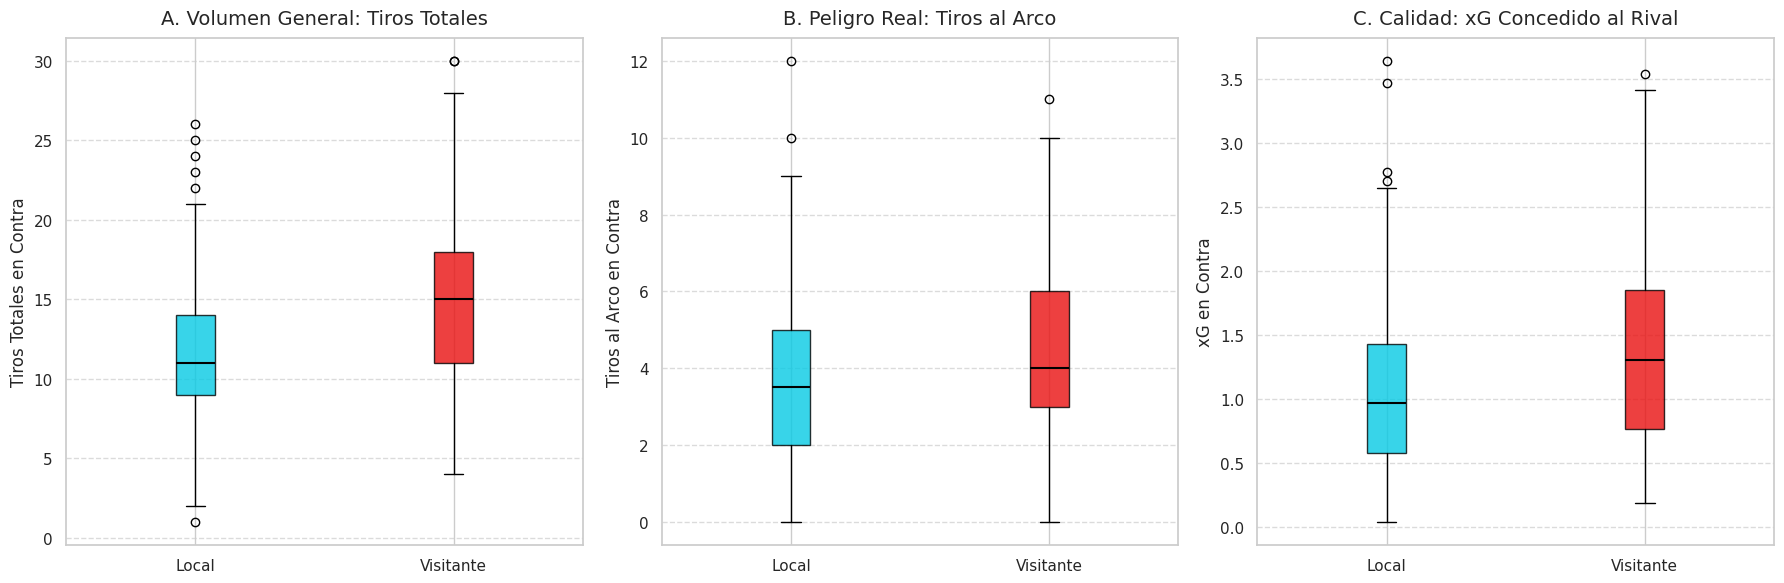

--- Medianas Globales ---
           Tiros Totales Concedidos  Tiros Arco Concedidos  xG Concedido
Condicion                                                               
Local                          11.0                    3.5          0.97
Visitante                      15.0                    4.0          1.30


In [ ]:


# 1. Transformación de los datos
df_local = df[['Local', 'Goles esperados (xG) (V)', 'Tiros al arco (V)', 'Tiros totales (V)']].copy()
df_local.columns = ['Equipo', 'xG Concedido', 'Tiros Arco Concedidos', 'Tiros Totales Concedidos']
df_local['Condicion'] = 'Local'

df_visita = df[['Visitante', 'Goles esperados (xG) (L)', 'Tiros al arco (L)', 'Tiros totales (L)']].copy()
df_visita.columns = ['Equipo', 'xG Concedido', 'Tiros Arco Concedidos', 'Tiros Totales Concedidos']
df_visita['Condicion'] = 'Visitante'

# Unimos ambos dataframes apilándolos
df_defensa = pd.concat([df_local, df_visita], ignore_index=True)

# 2. Configuración de los gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
variables = [
    ('Tiros Totales Concedidos', 'A. Volumen General: Tiros Totales', 'Tiros Totales en Contra'),
    ('Tiros Arco Concedidos', 'B. Peligro Real: Tiros al Arco', 'Tiros al Arco en Contra'),
    ('xG Concedido', 'C. Calidad: xG Concedido al Rival', 'xG en Contra')
]

data_local = df_defensa[df_defensa['Condicion'] == 'Local']
data_visita = df_defensa[df_defensa['Condicion'] == 'Visitante']
colores = ['#06cae4', '#e91010'] # Celeste (Local), Rojo (Visitante)

# 3. Generación de los Boxplots
for i, (columna, titulo, ylabel) in enumerate(variables):
    bplot = axes[i].boxplot([data_local[columna].dropna(), data_visita[columna].dropna()],
                            patch_artist=True)

    # Etiquetas de eje X puestas manualmente para evitar errores de versión
    axes[i].set_xticks([1, 2], ['Local', 'Visitante'])
    axes[i].set_title(titulo, fontsize=14, pad=10)
    axes[i].set_ylabel(ylabel)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

    for patch, color in zip(bplot['boxes'], colores):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)
    for median in bplot['medians']:
        median.set_color('black')
        median.set_linewidth(1.5)

plt.tight_layout()
plt.savefig('analisis_global_defensa_embudo.png', dpi=300, bbox_inches='tight')
plt.show()

# Resumen estadístico (mediana) para fundamentar el texto
print("--- Medianas Globales ---")
print(df_defensa.groupby('Condicion')[['Tiros Totales Concedidos', 'Tiros Arco Concedidos', 'xG Concedido']].median())

1. **Gráfico A — Volumen General (Tiros Totales):** La primera línea de contención táctica se rompe de visitante. La mediana de tiros totales concedidos al rival sufre un aumento masivo, pasando de 11.0 remates (cuando el equipo defiende de local) a 15.0 remates por partido (de visitante). Este salto en el volumen demuestra que el bloque defensivo es incapaz de restringir los espacios y la tenencia rival lejos de su propia área.

2. **Gráfico B — Peligro Real (Tiros al Arco):** El volumen general se traduce directamente en exigencia para el arquero. La mediana de tiros al arco asciende de 3.5 (local) a 4.0 (visitante). Además, el bloque central de los datos (la caja roja) se ubica notablemente por encima de la celeste, indicando que el "piso" de remates a los tres palos que sufre un equipo fuera de casa es sistemáticamente más alto en cualquier fecha del torneo.

3. **Gráfico C — Calidad de la Ocasión (xG):** El hallazgo final del embudo reside en la calidad de esas llegadas. La mediana de Goles Esperados () que permite un equipo local se sitúa en 0.97, consolidando una defensa sólida que, en promedio, resiste por debajo del gol. Sin embargo, al jugar de visitante, la calidad de las ocasiones permitidas se dispara a 1.30 xG. El ensanchamiento de la caja roja revela que defender fuera de casa no solo eleva la gravedad del peligro, sino que vuelve a la estructura defensiva mucho más errática e impredecible.

**Conclusión Global:** Abandonar el propio estadio produce una descompensación táctica severa en todas las capas defensivas. El equipo cede el control territorial permitiendo muchos más remates (Tiros Totales), lo que desemboca en mayor trabajo para su arquero (Tiros al Arco) proveniente de posiciones mucho más ventajosas para el rival ().



2. Grandes vs. Resto:

Una vez comprobado que el "efecto visitante" vulnera las defensas a nivel global, resulta pertinente analizar si la jerarquía del plantel y el peso institucional logran mitigar este problema.

Para ello, dividiremos a la liga en dos categorías: los "5 Grandes" (Boca Juniors, River Plate, Racing Club, Independiente y San Lorenzo) y el "Resto" de los equipos. El objetivo es comparar los promedios defensivos de ambos grupos cruzados por su condición de local o visitante mediante gráficos de barras agrupadas.

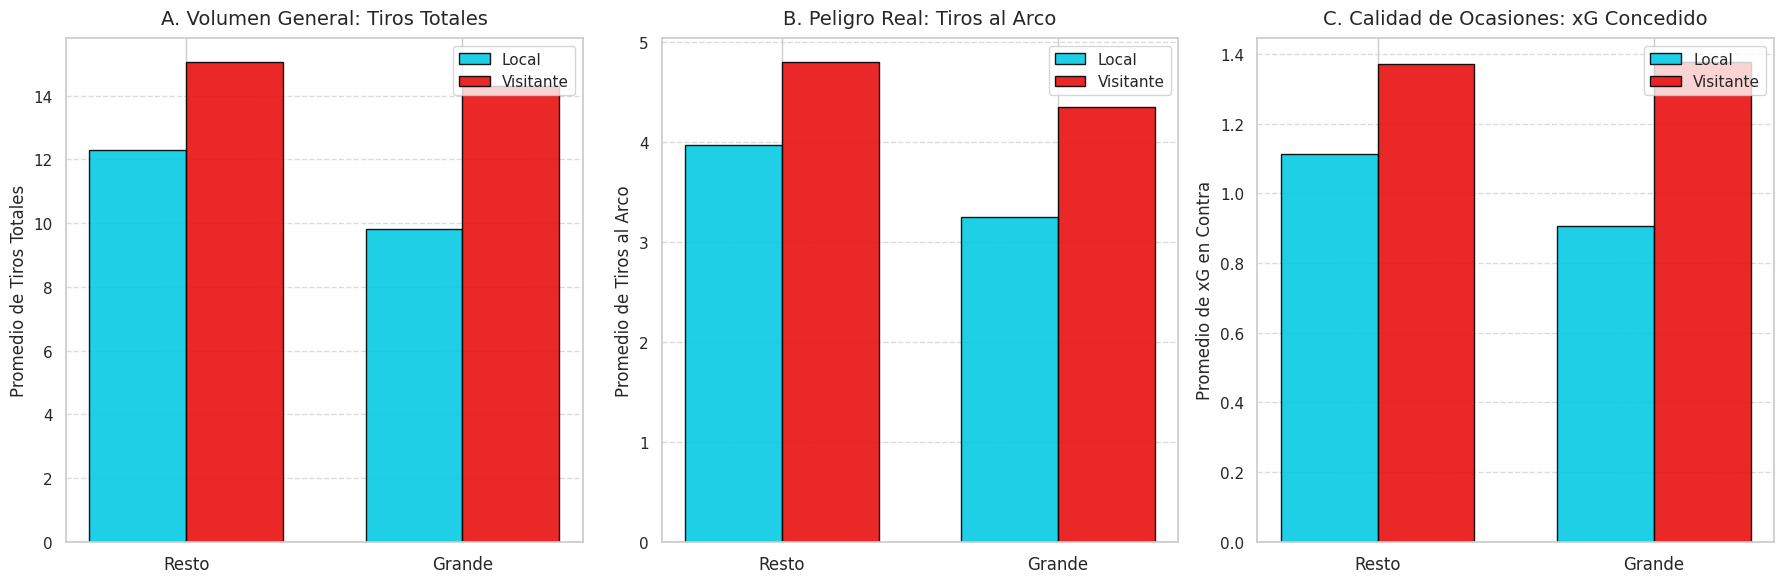

--- Promedios por Jerarquía y Condición ---
                     Tiros Totales Concedidos  Tiros Arco Concedidos  \
Jerarquia Condicion                                                    
Grande    Local                          9.82                   3.24   
          Visitante                     14.31                   4.34   
Resto     Local                         12.28                   3.96   
          Visitante                     15.06                   4.80   

                     xG Concedido  
Jerarquia Condicion                
Grande    Local              0.91  
          Visitante          1.38  
Resto     Local              1.11  
          Visitante          1.37  


In [ ]:
# 1. Preparación de la variable Jerarquía
grandes = ['Boca Juniors', 'River Plate', 'Racing Club', 'CA Independiente', 'San Lorenzo']

# Usamos df_defensa (asegurate de haber corrido la celda de la Parte Global antes)
df_defensa['Jerarquia'] = df_defensa['Equipo'].apply(lambda x: 'Grande' if x in grandes else 'Resto')

# 2. Agrupación de datos (calculamos los promedios)
df_agrupado = df_defensa.groupby(['Jerarquia', 'Condicion'])[['Tiros Totales Concedidos', 'Tiros Arco Concedidos', 'xG Concedido']].mean().reset_index()

# Separamos en dos dataframes para facilitar el gráfico de barras agrupadas
df_local_jer = df_agrupado[df_agrupado['Condicion'] == 'Local'].set_index('Jerarquia')
df_visita_jer = df_agrupado[df_agrupado['Condicion'] == 'Visitante'].set_index('Jerarquia')

# Ordenamos para que 'Resto' aparezca a la izquierda y 'Grande' a la derecha
orden = ['Resto', 'Grande']
df_local_jer = df_local_jer.reindex(orden)
df_visita_jer = df_visita_jer.reindex(orden)

# 3. Configuración de los gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ACUALIZADO: Usamos Tiros Totales en el primer gráfico
variables_barras = [
    ('Tiros Totales Concedidos', 'A. Volumen General: Tiros Totales', 'Promedio de Tiros Totales'),
    ('Tiros Arco Concedidos', 'B. Peligro Real: Tiros al Arco', 'Promedio de Tiros al Arco'),
    ('xG Concedido', 'C. Calidad de Ocasiones: xG Concedido', 'Promedio de xG en Contra')
]

x = np.arange(len(orden))  # Posiciones en el eje X (0 y 1)
ancho = 0.35  # Ancho de las barras
colores_barras = ['#06cae4', '#e91010'] # Celeste (Local) y Rojo (Visitante)

# 4. Generación de Barplots
for i, (columna, titulo, ylabel) in enumerate(variables_barras):
    # Dibujamos las barras de Locales (desplazadas a la izquierda)
    axes[i].bar(x - ancho/2, df_local_jer[columna], ancho, label='Local',
                color=colores_barras[0], edgecolor='black', alpha=0.9)
    # Dibujamos las barras de Visitantes (desplazadas a la derecha)
    axes[i].bar(x + ancho/2, df_visita_jer[columna], ancho, label='Visitante',
                color=colores_barras[1], edgecolor='black', alpha=0.9)

    # Formato de títulos y ejes
    axes[i].set_title(titulo, fontsize=14, pad=10)
    axes[i].set_ylabel(ylabel)
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(orden, fontsize=12)
    axes[i].legend()
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('analisis_jerarquia_defensa_embudo.png', dpi=300, bbox_inches='tight')
plt.show()

# Imprimir promedios para ver los números exactos
print("--- Promedios por Jerarquía y Condición ---")
print(df_agrupado.set_index(['Jerarquia', 'Condicion']).round(2))

A partir de los resultados expuestos en los gráficos de barras y la tabla de promedios, se observa el impacto de la localía según la jerarquía de los equipos:

**Promedio de Tiros Totales Concedidos:** En condición de local, los equipos Grandes conceden un promedio de 9.82 remates totales por partido, una cifra inferior a los 12.28 que recibe el Resto. Sin embargo, al jugar de visitante, el promedio de los equipos Grandes asciende a 14.31 tiros totales, acercándose a los 15.06 que promedia el Resto en esa misma condición.

**Promedio de Tiros al Arco Concedidos:** La tendencia se mantiene al analizar los remates efectivos. Como locales, los equipos Grandes promedian 3.24 tiros al arco recibidos por partido. Al salir de su estadio, esta cifra se incrementa a 4.34, superando el promedio de tiros al arco que recibe el Resto cuando juega en condición de local (3.96).

**Promedio de xG Concedido:** En sus estadios, los equipos Grandes limitan los Goles Esperados del rival a un promedio de 0.91. Al defender como visitantes, este indicador sube a 1.38 xG. Este valor es estadísticamente equivalente a los 1.37 xG que conceden los equipos del Resto en condición de visitante.

**Conclusión:** Las diferencias estadísticas entre los equipos Grandes y el Resto se observan principalmente en condición de local. Al jugar de visitante, la ventaja de los planteles de mayor jerarquía se diluye, mostrando niveles similares de tiros recibidos y goles esperados en contra que el resto de los equipos de la liga.

**3. Los 5 Grandes entre sí: Análisis de Rendimiento Individual**

En este último apartado, aislaremos a los 5 equipos de mayor envergadura (Boca Juniors, River Plate, Racing Club, Independiente y San Lorenzo) para analizar el comportamiento individual de sus sistemas defensivos.

Se utilizan gráficos de dispersión que cruzan el promedio de las métricas en condición de local (Eje X) frente a la condición de visitante (Eje Y). La línea diagonal punteada representa un rendimiento idéntico en ambas condiciones. Los puntos situados por encima de esta línea indican un deterioro en las estadísticas defensivas al salir del propio estadio.

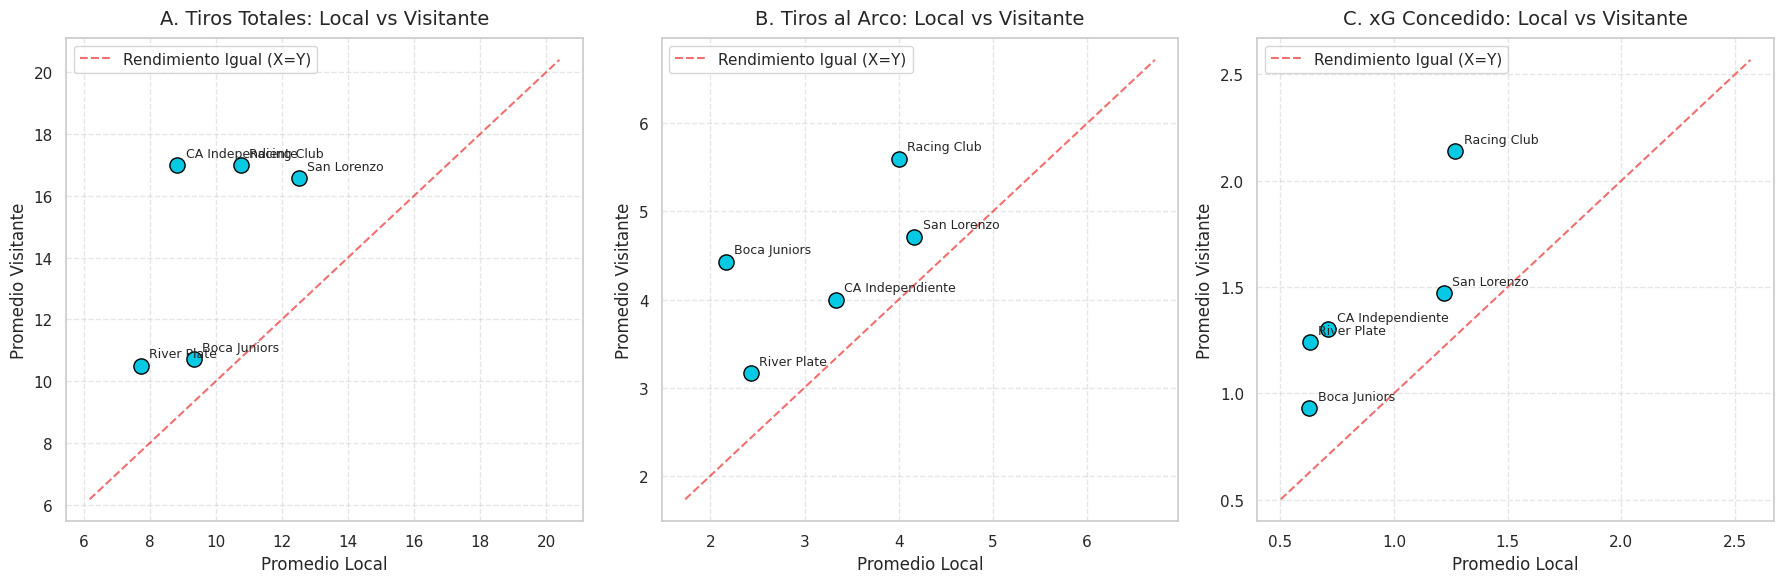

--- Promedios Individuales (Los 5 Grandes) ---
                 Tiros Totales Concedidos           Tiros Arco Concedidos  \
Condicion                           Local Visitante                 Local   
Equipo                                                                      
Boca Juniors                         9.33     10.71                  2.17   
CA Independiente                     8.83     17.00                  3.33   
Racing Club                         10.75     17.00                  4.00   
River Plate                          7.71     10.50                  2.43   
San Lorenzo                         12.50     16.57                  4.17   

                           xG Concedido            
Condicion        Visitante        Local Visitante  
Equipo                                             
Boca Juniors          4.43         0.63      0.93  
CA Independiente      4.00         0.71      1.30  
Racing Club           5.60         1.27      2.14  
River Plate           3.

In [468]:
# 1. Filtrar solo a los 5 Grandes
grandes = ['Boca Juniors', 'River Plate', 'Racing Club', 'CA Independiente', 'San Lorenzo']
df_grandes = df_defensa[df_defensa['Equipo'].isin(grandes)]

# 2. Agrupar por Equipo y Condición, calculando la media
# Usamos unstack() para tener 'Local' y 'Visitante' en distintas columnas y facilitar el ploteo de X e Y
df_g_agrupado = df_grandes.groupby(['Equipo', 'Condicion'])[['Tiros Totales Concedidos', 'Tiros Arco Concedidos', 'xG Concedido']].mean().unstack('Condicion')

# 3. Configuración de los gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

variables_scatter = [
    ('Tiros Totales Concedidos', 'A. Tiros Totales: Local vs Visitante'),
    ('Tiros Arco Concedidos', 'B. Tiros al Arco: Local vs Visitante'),
    ('xG Concedido', 'C. xG Concedido: Local vs Visitante')
]

# 4. Generación de Scatterplots mediante un bucle
for i, (columna, titulo) in enumerate(variables_scatter):
    # Definir ejes X (Local) e Y (Visitante)
    x = df_g_agrupado[(columna, 'Local')]
    y = df_g_agrupado[(columna, 'Visitante')]

    # Graficar los puntos
    axes[i].scatter(x, y, color='#06cae4', edgecolor='black', s=120, zorder=5)

    # Trazar la línea diagonal de "rendimiento idéntico"
    min_val = min(x.min(), y.min()) * 0.8
    max_val = max(x.max(), y.max()) * 1.2
    axes[i].plot([min_val, max_val], [min_val, max_val], color='#e91010', linestyle='--', alpha=0.6, label='Rendimiento Igual (X=Y)')

    # Etiquetar cada punto con el nombre del equipo
    for equipo in df_g_agrupado.index:
        axes[i].annotate(equipo,
                         (df_g_agrupado.loc[equipo, (columna, 'Local')],
                         df_g_agrupado.loc[equipo, (columna, 'Visitante')]),
                         xytext=(6, 6), textcoords='offset points', fontsize=9, zorder=10)

    # Formato
    axes[i].set_title(titulo, fontsize=14, pad=10)
    axes[i].set_xlabel('Promedio Local')
    axes[i].set_ylabel('Promedio Visitante')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend()

plt.tight_layout()
plt.savefig('analisis_individual_grandes.png', dpi=300, bbox_inches='tight')
plt.show()

# Imprimir la tabla de datos subyacente para redactar el análisis posterior
print("--- Promedios Individuales (Los 5 Grandes) ---")
print(df_g_agrupado.round(2))

**Análisis de Resultados: Comportamiento Individual de los 5 Grandes**

A partir de los gráficos de dispersión, que relacionan el promedio de las métricas en condición de local (eje X) frente a la condición de visitante (eje Y), se observa el comportamiento específico de cada uno de los 5 Grandes:

**Ubicación respecto a la línea de igualdad:** En los tres gráficos (Tiros Totales, Tiros al Arco y xG Concedido), los equipos se posicionan sistemáticamente por encima de la línea diagonal punteada (donde el valor de X es mayor que el de Y). Esto demuestra gráficamente que las concesiones defensivas aumentan en todos los clubes al jugar fuera de casa.

**Volumen de remates (Gráficos A y B):** Al observar la dispersión de los puntos, se evidencia que ningún equipo logra mantener su nivel de restricción de tiros al salir de su estadio. Los puntos sufren un desplazamiento vertical evidente, lo que indica un mayor sufrimiento de remates totales y al arco en condición de visitante, independientemente del club analizado.

**Calidad de las ocasiones (Gráfico C):** En términos de Goles Esperados (xG) en contra, se observa que aquellos equipos que logran solidez de local (ubicándose por debajo de 1.00 en el eje X), sufren un deterioro marcado de visitante. La dispersión en el eje Y muestra que la calidad de las ocasiones permitidas al rival se incrementa de forma generalizada.

**Conclusión:** El análisis individual ratifica la tendencia observada en los promedios agrupados. Ninguno de los 5 Grandes presenta un sistema defensivo inmune a la localía. El incremento en las llegadas y en la calidad de las ocasiones del rival afecta a todos estos planteles al momento de defender en condición de visitante.

**Cierre del Análisis Defensivo: Vulnerabilidad y Efectividad Real**

Tras analizar las métricas de volumen y peligro (tiros recibidos y xG concedido), observamos una tendencia general clara: los equipos suelen quedar más expuestos cuando juegan fuera de casa. Ahora bien, la pregunta clave para cerrar este bloque es: **¿esta mayor vulnerabilidad estructural de visitante se refleja de manera directa en los goles que efectivamente reciben en el arco?**

**Diferencial positivo (Celeste):** Confirma la ventaja de la localía. El equipo logró proteger mejor su arco en casa, "ahorrándose" goles respecto a sus partidos afuera.
**Diferencial negativo (Rojo):** Muestra un comportamiento atípico donde el equipo sufrió una mayor cantidad de goles jugando ante su gente que saliendo de visitante.

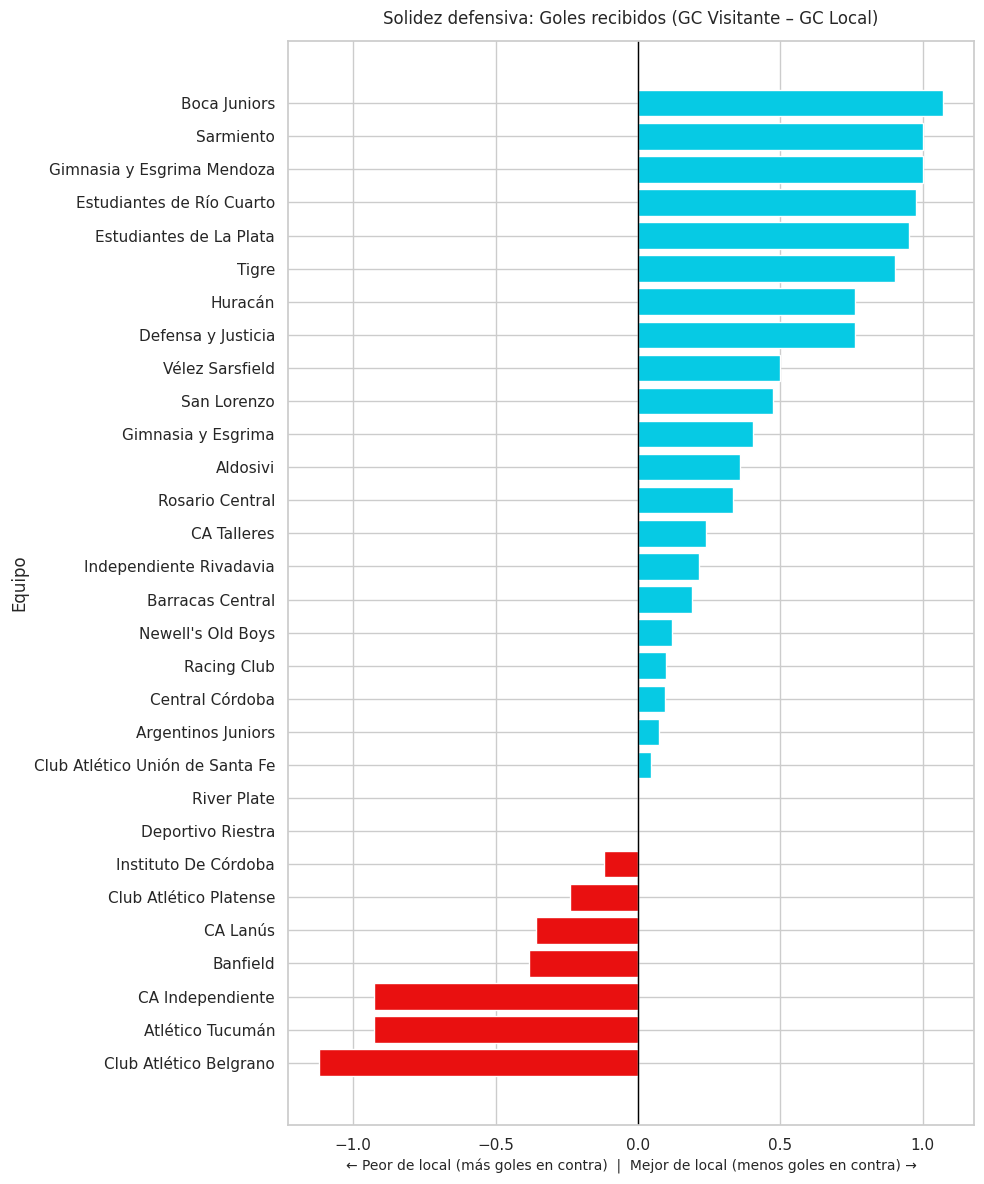

In [469]:

df_diff = pd.DataFrame({'gc_local': df.groupby('Local')['Resultado (V)'].mean(), 'gc_visita': df.groupby('Visitante')['Resultado (L)'].mean()}).dropna()

# Valores positivos = defendió MEJOR de local (recibió menos goles)
df_diff['solidez_defensiva'] = df_diff['gc_visita'] - df_diff['gc_local']

# Ordenar de menor a mayor para el gráfico horizontal
df_diff = df_diff.sort_values('solidez_defensiva', ascending=True)

# 2. Gráfico de barras horizontales
fig, ax = plt.subplots(figsize=(10, 12))

# Rojo si recibió más goles de local, celeste/azul si recibió menos goles de local
colores = ['#e91010' if val < 0 else '#06cae4' for val in df_diff['solidez_defensiva']]

# Se cambia df_diff['Equipo'] por df_diff.index para usar el nombre del equipo:
ax.barh(df_diff.index, df_diff['solidez_defensiva'], color=colores)

ax.axvline(0, color='black', linewidth=1)

# Título y etiquetas
ax.set_title('Solidez defensiva: Goles recibidos (GC Visitante – GC Local)', fontsize=12, pad=12)
ax.set_xlabel('← Peor de local (más goles en contra)  |  Mejor de local (menos goles en contra) →', fontsize=10)
ax.set_ylabel('Equipo')

plt.tight_layout()
plt.savefig('diferencia_goles_recibidos_corregido.png', dpi=300, bbox_inches='tight')
plt.show()

**Conclusión: La Localía en el Arco Propio**

El análisis confirma que la vulnerabilidad estructural fuera de casa (mayor volumen de tiros y xG concedido) impacta directamente en el marcador final:

**Efecto directo en el resultado**: 18 de los 30 equipos (60%) sufrieron más goles jugando de visitante, lo que representa exactamente el doble respecto a los 9 que recibieron más goles en su cancha (3 registraron la misma cantidad).
**Síntesis**: Para la gran mayoría de la liga, la localía funciona como un escudo real: la exposición al jugar afuera se traduce directamente en goles en contra.